## **Ziel**

Das Notebook übersetzt das Kernmodell der Systemkarte aus LE1 in ein quantitatives System-Dynamics-Modell. Untersucht wird, wie stark Dürren über Ertrag und Einkommen die dauerhafte Abwanderung aus der Region Kaffrine (Senegal) erhöhen und wie die Abwanderung über Bevölkerung, Netzwerke und Rücküberweisungen auf die Region zurückwirkt.

## **Rahmen**

- **System:** Region Kaffrine im Sahel, Bevölkerung, Landwirtschaft und Abwanderung
- **Grundlage:** Causal Loop Map aus `LE1_system_mapping/01_system_map.md`
- **Werkzeug:** BPTK-Py, der gesamte Code für Daten, Modell und Auswertung steht in diesem Notebook
- **Zeitraum:** **2013** bis **2023** für den Backtest, **2024** bis **2050** für Szenarien

## **Kapitelübersicht**

| Kapitel | Inhalt |
|---|---|
| `2.1) Problemstellung und Systemgrenzen` | Fragestellung, Kenngrössen, Abgrenzung |
| `2.2) Daten` | Niederschlag, Bevölkerung, Migration, Ertrag |
| `2.3) Modellstruktur` | Stocks, Flows, Converter, Verzögerung, Schleifen, Umsetzung in BPTK-Py |
| `2.4) Zeitschritt und Parameter` | Zeithorizont, Parametertabelle, Kalibrierung |
| `2.5) Basislauf` | Entwicklung ohne zusätzliche Dürren |
| `2.6) Validierung` | Backtest, Test ausserhalb der Stichprobe, numerische Robustheit, Plausibilitätsprüfung |
| `2.7) Szenarien` | wiederkehrende Dürren und trockeneres Klima |
| `2.8) Sensitivität` | Parameterbandbreiten, Verzögerung, Ertragstrend, R1 oder B1 |
| `2.9) Erkenntnisse und Limitationen` | Zusammenfassung und Grenzen des Modells |

## **Glossar**

| Begriff | Bedeutung |
|---|---|
| Stock | Bestand, der sich über die Zeit ansammelt, z. B. Bevölkerung in Personen |
| Flow | Zu- oder Abfluss eines Stocks pro Zeiteinheit, z. B. Abwanderung in Personen pro Jahr |
| Biflow | Flow, der positiv und negativ sein kann |
| Converter | berechnete Hilfsgrösse ohne eigenes Gedächtnis, z. B. ein Index |
| Index | dimensionslose Grösse, 1 entspricht dem Referenzzustand (Normaljahr, Stand **2013**) |
| Elastizität | prozentuale Änderung einer Grösse bei 1 % Änderung einer anderen |
| Verstärkende Schleife (R) | Rückkopplung, die eine Änderung weiter verstärkt |
| Ausgleichende Schleife (B) | Rückkopplung, die einer Änderung entgegenwirkt |
| Verzögerung erster Ordnung | eine Grösse passt sich mit einer Zeitkonstante an ihren Zielwert an |
| Zeitschritt `dt` | Länge eines Rechenschritts der Simulation |
| Kalibrierung | Parameter so einstellen, dass das Modell einen beobachteten Wert trifft |
| Backtest | Vergleich der Simulation mit beobachteten Werten der Vergangenheit |
| Szenario | konsistente Was-wäre-wenn-Annahme über die Zukunft, keine Prognose |
| Sensitivitätsanalyse | Prüfung, wie stark Ergebnisse auf Parameteränderungen reagieren |

In [1]:
#------------------------------------------------------------------------------
# Pakete, Konstanten und Anzeigeformat
#------------------------------------------------------------------------------
import warnings
from dataclasses import asdict, dataclass, replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", message="pkg_resources is deprecated")
from BPTK_Py import Model, bptk
from BPTK_Py import sd_functions as sd

%matplotlib inline

DATA_RAW = Path("..") / "data" / "raw"  # Rohdaten relativ zum Notebook
REFERENZ = (1991, 2020)                  # Normalperiode für den Niederschlag
LETZTES_DATENJAHR = 2023                 # danach Szenarien


def zahl(x, nachkomma=0):
    """Zahl mit Tausendertrennzeichen ' und Dezimalpunkt."""
    return f"{x:,.{nachkomma}f}".replace(",", "'")


def prozent(x, nachkomma=1, vorzeichen=False):
    return f"{x * 100:{'+' if vorzeichen else ''}.{nachkomma}f} %"


pd.set_option("display.float_format", lambda x: zahl(x, 3))

## **2.1) Problemstellung und Systemgrenzen**

Das Kapitel legt fest, welche Frage das Modell beantwortet und welche Teile des Systems aus LE1 übernommen werden.

### **2.1.1) Fragestellung und Kenngrössen**

Dürren senken in Kaffrine die Ernte des Regenfeldbaus und damit Einkommen und Versorgung. Gefragt wird, wie stark dies die Abwanderung erhöht und welche Rückkopplungen die Wirkung verstärken oder dämpfen.

- **Fragestellung:** Wie stark treiben Dürren die Abwanderung aus Kaffrine, und wie wirkt die Abwanderung über Bevölkerung, Versorgung, Netzwerke und Rücküberweisungen auf die Region zurück?
- **Kenngrössen:**
  - Bevölkerung (Personen)
  - Abwanderung (Personen pro Jahr)
  - Abwanderungsrate (pro Jahr)
  - Abgewanderte Personen im Netzwerk (Personen)
- **Migrationsbegriff:** dauerhafte Abwanderung, also ein Wechsel des Wohnorts über die Regionsgrenze. Grundlage ist das Fünfjahresfenster der Volkszählung. Saisonale und zirkuläre Migration sind nicht abgebildet
- **Szenarien:** nötig, weil der Niederschlag nach **2023** unbekannt ist

### **2.1.2) Systemgrenzen**

Grundlage ist Teil 01 der Causal Loop Map aus LE1. Alle Grössen innerhalb der Grenze werden im Modell berechnet, Grössen ausserhalb wirken nur als Vorgabe oder gar nicht.

![Causal Loop Map](../LE1_system_mapping/causal_loop_map.png)

- **Von aussen vorgegeben:**
  - Niederschlag, bis **2023** aus Daten, danach als Szenario
  - Produktivitätstrend des Ertrags, bis **2023** aus Daten, danach als Annahme
  - Natürliches Wachstum, bis **2023** aus den Volkszählungen, danach konstant
- **Im Modell berechnet:**
  - Bevölkerung, Abwanderung, Zuzug und Abgewanderte als Stocks und Flows
  - Ertrag, Produktion, Einkommen pro Kopf, Nahrung pro Person und Rücküberweisungen als Index
- **Vereinfacht:**
  - Wasserverfügbarkeit als normierter Niederschlag, keine eigene Wasserbilanz
  - Zuzug mit konstanter Rate
  - Rückkehr nur indirekt über die Verweildauer im Netzwerk
- **Ausserhalb:** Zielorte, saisonale Migration, Preise, Bewässerung, Politik und Konflikte

Die Systemgrenze folgt den verfügbaren Daten. Für Preise, Bewässerung und Konflikte gibt es auf Ebene der Region keine Zeitreihen, und Bewässerung wird in LE4 als Handlungsoption behandelt.

## **2.2) Daten**

Alle Rohdaten liegen unverändert in `data/raw/`, die Quellen sind in `data/SOURCES.md` dokumentiert. Die Aufbereitung geschieht in den Code-Zellen dieses Kapitels.

### **2.2.1) Niederschlag**

Der Jahresniederschlag ist der Klimatreiber des Modells. Er wird als Index relativ zur Normalperiode **1991** bis **2020** verwendet, damit ein Normaljahr den Wert 1 hat.

**Daten (raw):**
- `chirps_kaffrine_1991_2023.csv`: Jahresniederschlag CHIRPS v2.0, Rasterzellen von 0.05° im Rechteck um Kaffrine (13.6 bis 14.7° N, 16.0 bis 14.4° W)

**Vorgehen:**
1. Mittel über alle Rasterzellen je Jahr bilden
2. Mittelwert **1991** bis **2020** als Referenz berechnen

Normalperiode 1991-2020: 569 mm/Jahr
Trockenstes Jahr seit 2013: 2014 mit Index 0.74


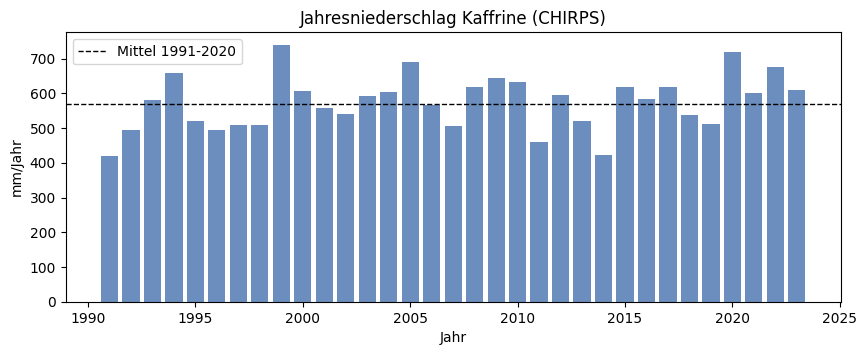

In [2]:
#------------------------------------------------------------------------------
# Niederschlag laden und darstellen
#------------------------------------------------------------------------------
def lade_niederschlag():
    """Jahresniederschlag Kaffrine (mm), Mittel über alle CHIRPS-Rasterzellen, und Referenz 1991-2020."""
    raw = pd.read_csv(DATA_RAW / "chirps_kaffrine_1991_2023.csv", skiprows=[1])  # 2. Zeile: Einheiten
    raw["jahr"] = pd.to_datetime(raw["time"]).dt.year
    reihe = raw[raw["jahr"] <= LETZTES_DATENJAHR].groupby("jahr")["precip"].mean()
    ref = reihe.loc[REFERENZ[0]:REFERENZ[1]].mean()
    return reihe, ref


niederschlag, ref = lade_niederschlag()
print(f"Normalperiode 1991-2020: {zahl(ref)} mm/Jahr")
print(f"Trockenstes Jahr seit 2013: {niederschlag.loc[2013:].idxmin()} mit Index {niederschlag.loc[2013:].min() / ref:.2f}")

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(niederschlag.index, niederschlag, color="#6c8ebf")
ax.axhline(ref, color="black", lw=1, ls="--", label="Mittel 1991-2020")
ax.set(xlabel="Jahr", ylabel="mm/Jahr", title="Jahresniederschlag Kaffrine (CHIRPS)")
ax.legend()
plt.show()

#### **Erkenntnisse**

Der Niederschlag schwankt stark von Jahr zu Jahr, ein Trend ist in der kurzen Reihe nicht erkennbar.

- **Referenz:** Ein Normaljahr bringt **569** mm
- **Dürre im Backtest:** **2014** ist mit einem Index von **0.74** das trockenste Jahr seit **2013** und dient als Testfall für die Verzögerung

Mit dem Niederschlag als Treiber fehlen noch die Grössen, auf die er wirkt.

### **2.2.2) Bevölkerung und Migration**

Bevölkerung und Migration bestimmen Anfangszustand, Migrationsraten und Backtest. Verwendet werden nur beobachtete Volkszählungswerte, Schätzungen und Projektionen dienen höchstens als Vergleich.

**Daten (raw):**
- `ansd_bevoelkerung_kaffrine.csv`: Volkszählungen **2013** und **2023**, Schätzungen und ANSD-Projektion bis **2050**
- `ansd_migration_kaffrine_2023.csv`: Wegzüge und Zuzüge innerhalb Senegals und international, Volkszählungen **2013** und **2023**, verschiedene Zeitfenster

**Vorgehen:**
1. Beobachtetes Bevölkerungswachstum **2013** bis **2023** berechnen
2. Jährliche Wegzugs- und Zuzugsraten aus den Fünfjahresfenstern beider Volkszählungen ableiten, Nenner ist die Bevölkerung in der Mitte des Fensters
3. Zum Vergleich die Rate aus dem Einjahresfenster **2022** bis **2023** berechnen

In [3]:
#------------------------------------------------------------------------------
# Bevölkerung und Migrationsraten
#------------------------------------------------------------------------------
def lade_bevoelkerung(datentyp=None):
    """Bevölkerungsreihe laden; optional auf einen Datentyp filtern."""
    raw = pd.read_csv(DATA_RAW / "ansd_bevoelkerung_kaffrine.csv")
    if datentyp is not None:
        datentypen = [datentyp] if isinstance(datentyp, str) else list(datentyp)
        raw = raw[raw["datentyp"].isin(datentypen)]
    return raw.set_index("jahr")["bevoelkerung"]


def lade_migration(vollstaendig=False):
    """Migration laden; standardmässig als Series (Index: Kennung der Grösse)."""
    raw = pd.read_csv(DATA_RAW / "ansd_migration_kaffrine_2023.csv")
    if vollstaendig:
        return raw
    return raw.set_index("groesse")["personen"]


def migrationsraten(migration, bevoelkerung_2013, bevoelkerung_2023):
    """
    Jährliche Wegzugs- und Zuzugsraten aus den Fünfjahresfenstern der Volkszählungen 2013 und 2023.
    Nenner ist die Bevölkerung in der Mitte des Fensters, interpoliert mit dem beobachteten Wachstum.
    """
    wachstum = np.log(bevoelkerung_2023 / bevoelkerung_2013) / 10
    mitte_2023 = bevoelkerung_2013 * np.exp(wachstum * 7.5)   # Mai 2018 bis Ende 2023
    mitte_2013 = bevoelkerung_2013 * np.exp(-wachstum * 2.5)  # 2008 bis 2013
    return pd.DataFrame({
        "Fenster 2018-2023": {"wegzug": migration["wegzuege_5_jahre"] / 5 / mitte_2023,
                              "zuzug": migration["zuzuege_5_jahre"] / 5 / mitte_2023},
        "Fenster 2008-2013": {"wegzug": migration["wegzuege_5_jahre_2013"] / 5 / mitte_2013,
                              "zuzug": migration["zuzuege_5_jahre_2013"] / 5 / mitte_2013},
    }).T


bevoelkerung = lade_bevoelkerung()
bev_beobachtet = lade_bevoelkerung("Volkszaehlung").loc[[2013, 2023]]
bev_projektion = lade_bevoelkerung("Projektion")
migration = lade_migration()

wachstum_beobachtet = np.log(bev_beobachtet[2023] / bev_beobachtet[2013]) / 10
raten = migrationsraten(migration, bev_beobachtet[2013], bev_beobachtet[2023])
rate_1_jahr = migration["wegzuege_1_jahr_2023"] / bev_beobachtet[2023]

print(f"Bevölkerung 2013: {zahl(bev_beobachtet[2013])}   2023: {zahl(bev_beobachtet[2023])}")
print(f"Beobachtetes Wachstum 2013-2023: {prozent(wachstum_beobachtet, 2)} pro Jahr")
print(f"Wegzugsrate Einjahresfenster 2022-2023: {prozent(rate_1_jahr, 2)} pro Jahr")
raten.style.format(lambda x: prozent(x, 2))

Bevölkerung 2013: 566'992   2023: 820'405
Beobachtetes Wachstum 2013-2023: 3.69 % pro Jahr
Wegzugsrate Einjahresfenster 2022-2023: 3.16 % pro Jahr


,wegzug,zuzug
Fenster 2018-2023,0.74 %,0.36 %
Fenster 2008-2013,1.27 %,0.66 %


#### **Erkenntnisse**

Die Bevölkerung wächst stark, die dauerhafte Abwanderung ist im Verhältnis klein, und beide Volkszählungen liefern unterschiedliche Raten.

**Bevölkerung**
- Von **566'992** (**2013**) auf **820'405** Personen (**2023**), also **3.69 %** pro Jahr

**Migration**
- Im Fenster **2018** bis **2023** ziehen jährlich **0.74 %** weg und **0.36 %** zu
- Im Fenster **2008** bis **2013** waren es **1.27 %** und **0.66 %**. Die Wegzugsrate ist zwischen den Volkszählungen gesunken
- Das Einjahresfenster zeigt mit **3.16 %** eine rund viermal höhere Rate. Das deutet auf saisonale und zirkuläre Migration hin, die das Fünfjahresfenster nicht erfasst und das Modell nicht abbildet
- Internationale Wegzüge sind mit **2'447** Personen in fünf Jahren klein und kein eigener Flow

Das zweite Fenster wird nicht zur Parametrisierung verwendet, sondern als unabhängiger Vergleich im Backtest und als Bandbreite in der Sensitivitätsanalyse.

### **2.2.3) Ertrag**

Die Elastizität des Ertrags auf den Niederschlag ist der zentrale Parameter der Klimakette. Sie gibt an, um wie viel Prozent der Ertrag sinkt, wenn 1 % weniger Regen fällt.

**Daten (raw):**
- `ansd_ertrag_kaffrine.csv`: Ertrag in kg/ha für Hirse (Grundnahrungsmittel, **12** Jahre) und Erdnuss (wichtigste Einkommenskultur, **9** Jahre), **2009** bis **2023** ohne **2014** bis **2016**
- `niederschlag` aus Abschnitt `2.2.1) Niederschlag`

**Vorgehen:**
1. Je Kultur die Regression schätzen

$$\log(Y_t) = a + b \log(N_t) + c \, (t - \bar{t})$$

2. $Y_t$ ist der Ertrag, $N_t$ der Niederschlagsindex, $b$ die Elastizität und $c$ der Trend pro Jahr
3. Erträge und Niederschlag grafisch vergleichen

Der Trendterm ist nötig, weil die Erträge seit **2009** steigen und die Jahre ab **2019** überdurchschnittlich nass waren. Ohne Trend würde der Anstieg fälschlich dem Niederschlag zugeschrieben.

,n,elastizitaet,se_elastizitaet,trend,se_trend,r2
Erdnuss (arachide d'huilerie),9,0.94,0.38,2.2 %,0.9 %,0.74
Hirse (mil),12,0.46,0.17,5.1 %,0.4 %,0.95


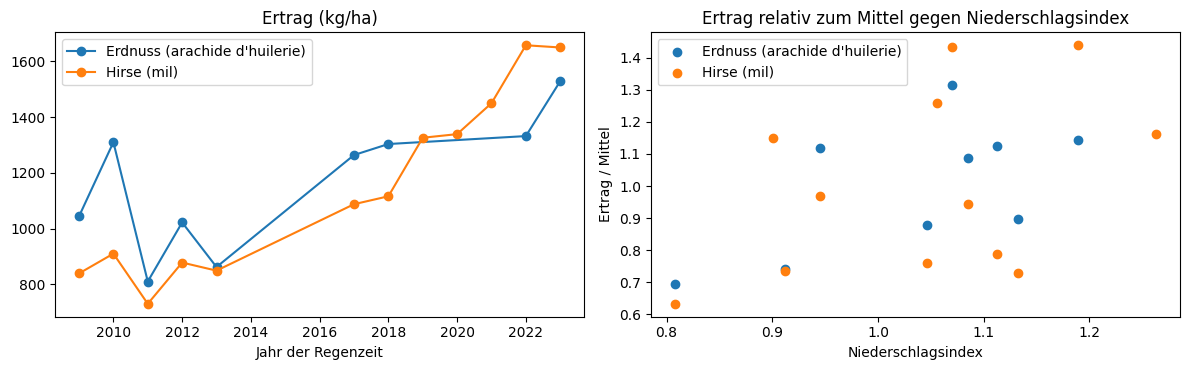

In [4]:
#------------------------------------------------------------------------------
# Elastizität und Trend des Ertrags schätzen
#------------------------------------------------------------------------------
def lade_ertrag(kultur=None):
    """Ertrag (kg/ha) je Jahr der Regenzeit und Kultur; optional eine Kultur als Series."""
    raw = pd.read_csv(DATA_RAW / "ansd_ertrag_kaffrine.csv")
    tab = raw.pivot(index="jahr", columns="kultur", values="ertrag_kg_ha")
    return tab if kultur is None else tab[kultur].dropna()


def schaetze_ertrag_elastizitaet(ertrag, niederschlag, ref, bis=None):
    """
    Regression log(Ertrag) = a + b * log(Niederschlagsindex) + c * (Jahr - t0).
    b ist die Elastizität des Ertrags auf den Niederschlag, c der Trend pro Jahr.
    Mit bis wird nur bis zu diesem Jahr geschätzt (Test ausserhalb der Stichprobe).
    """
    df = pd.DataFrame({"ertrag": ertrag, "index": niederschlag.reindex(ertrag.index) / ref}).dropna()
    if bis is not None:
        df = df.loc[:bis]
    t0 = df.index.values.mean()
    t = df.index.values - t0
    X = np.column_stack([np.ones(len(df)), np.log(df["index"]), t])
    y = np.log(df["ertrag"].values)
    b, *_ = np.linalg.lstsq(X, y, rcond=None)
    e = y - X @ b
    se = np.sqrt(np.diag(e @ e / (len(df) - 3) * np.linalg.inv(X.T @ X)))
    return {"n": len(df), "elastizitaet": b[1], "se_elastizitaet": se[1], "trend": b[2], "se_trend": se[2],
            "r2": 1 - e @ e / ((y - y.mean()) ** 2).sum(), "a": b[0], "t0": t0}


ertrag = lade_ertrag()
schaetzung = pd.DataFrame({k: schaetze_ertrag_elastizitaet(ertrag[k].dropna(), niederschlag, ref)
                           for k in ertrag.columns}).T.drop(columns=["a", "t0"])
display(schaetzung.style.format({"n": "{:.0f}", "elastizitaet": "{:.2f}", "se_elastizitaet": "{:.2f}",
                                 "trend": lambda x: prozent(x), "se_trend": lambda x: prozent(x),
                                 "r2": "{:.2f}"}))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for k in ertrag.columns:
    ertrag[k].dropna().plot(ax=axes[0], marker="o", label=k)
axes[0].set(title="Ertrag (kg/ha)", xlabel="Jahr der Regenzeit")
axes[0].legend()
for k in ertrag.columns:
    e = ertrag[k].dropna()
    axes[1].scatter(niederschlag.reindex(e.index) / ref, e / e.mean(), label=k)
axes[1].set(title="Ertrag relativ zum Mittel gegen Niederschlagsindex", xlabel="Niederschlagsindex", ylabel="Ertrag / Mittel")
axes[1].legend()
fig.tight_layout()
plt.show()

#### **Erkenntnisse**

Der Ertrag reagiert unterproportional auf den Niederschlag, und die Produktivität ist im Beobachtungszeitraum deutlich gestiegen.

**Elastizität**
- Hirse **0.46**, Erdnuss **0.94**. Das Modell rechnet mit einem einzigen Ertragsindex und verwendet das gerundete Mittel **0.7**
- Die Standardfehler sind mit **0.17** und **0.38** gross, die Schätzung ist unsicher

**Trend**
- Hirse **+5.1 %**, Erdnuss **+2.2 %** pro Jahr. Das Modell verwendet bis **2023** das gerundete Mittel von **3.5 %** pro Jahr
- Ob der Trend nach **2023** anhält, ist offen. Die Referenz rechnet mit Stagnation, fortgesetztes Wachstum wird als Variante geprüft

Damit sind Klimatreiber, Bevölkerung und Ertrag quantifiziert und können in die Modellstruktur übertragen werden.

## **2.3) Modellstruktur**

Die Knoten der Causal Loop Map werden in Stocks, Flows und Converter übersetzt. Jede Grösse erhält eine Einheit und eine Gleichung. Das Stock-and-Flow-Diagramm zeigt die Struktur des simulierten Modells, die Tabellen der folgenden Abschnitte die Gleichungen.

![Stock-and-Flow-Diagramm](stock_flow_diagram.png)

Quelle des Diagramms ist `stock_flow_diagram.dot` (Graphviz).

### **2.3.1) Stocks und Flows**

Stocks sind die Gedächtnisse des Systems, sie ändern sich nur über ihre Flows. Das Modell hat drei Stocks.

| Element | Typ | Einheit | Gleichung | Schleife |
|---|---|---|---|---|
| `bevoelkerung` | Stock | Personen | Zuflüsse `natuerliches_wachstum` und `zuzug`, Abfluss `abwanderung` | R1, B1, R3 |
| `abgewanderte` | Stock | Personen | Zufluss `abwanderung`, Abfluss `abgang_netzwerk` | R2, B2 |
| `druck_verzoegert` | Stock | Index | Biflow `anpassung_druck` | alle |
| `natuerliches_wachstum` | Flow | Personen/Jahr | `bevoelkerung` × `rate_natuerliches_wachstum` | R3 |
| `zuzug` | Flow | Personen/Jahr | `bevoelkerung` × `zuzugsrate` | |
| `abwanderung` | Flow | Personen/Jahr | `bevoelkerung` × `abwanderungsrate` | alle |
| `abgang_netzwerk` | Flow | Personen/Jahr | `abgewanderte` / `verweildauer` | R2, B2 |
| `anpassung_druck` | Biflow | Index/Jahr | (`druck` − `druck_verzoegert`) / `verzoegerung` | |

- **Anfangswert Bevölkerung:** Volkszählung **2013**
- **Anfangswert Abgewanderte:** Gleichgewicht von Zu- und Abgang im Normaljahr, also `abwanderungsrate_basis` × `bevoelkerung_0` × `verweildauer`. Das ist kein gemessener Bestand. Die **80'171** Lebenszeitwegzüge der Volkszählung **2023** dienen nur als Grössenordnung. Weil die Bevölkerung wächst, sinkt der Anteil der Abgewanderten an der Bevölkerung nach dem Start. Abschnitt `2.6.1) Backtest Bevölkerung und Migration` vergleicht diesen Rückgang mit den Volkszählungen

### **2.3.2) Wirkungskette und Abwanderungsdruck**

Die Converter bilden die Kette vom Niederschlag zur Abwanderung. Ertrag, Produktion, Einkommen und Nahrung sind Indizes, weil für Kaffrine keine Zeitreihen in Geldeinheiten vorliegen.

| Element | Einheit | Gleichung | Schleife |
|---|---|---|---|
| `niederschlag_index` | Index | `niederschlag` / Mittel **1991** bis **2020** | |
| `wasserverfuegbarkeit_index` | Index | gleich `niederschlag_index` (Proxy) | |
| `produktivitaet_index` | Index | $e^{g (t - 2013)}$ bis **2023**, danach Szenarioannahme | |
| `rate_natuerliches_wachstum` | 1/Jahr | **3.79 %** (**2013**) linear auf **3.36 %** (**2023**), danach konstant | R3 |
| `ertrag_index` | Index | (1 + `elast_ertrag` × (`wasserverfuegbarkeit_index` − 1)) × `produktivitaet_index` | |
| `produktion_index` | Index | `ertrag_index` × (1 + `elast_arbeit` × (`bevoelkerung` / `bevoelkerung_0` − 1)) | R1 |
| `nahrung_pk_index` | Index | `produktion_index` / (`bevoelkerung` / `bevoelkerung_0`) | Kenngrösse |
| `rueck_pk_index` | Index | (`abgewanderte` / `bevoelkerung`) / Anfangswert | B2 |
| `haushaltseinkommen_index` | Index | (1 − `anteil_rueck`) × Produktion pro Kopf + `anteil_rueck` × `rueck_pk_index` | R1, B1, B2 |
| `druck` | Index | `wirkung_einkommen` × (1 − `haushaltseinkommen_index`) | R1, B1, B2 |
| `netzwerk_faktor` | Index | 1 + `wirkung_netzwerk` × ((`abgewanderte` / `bevoelkerung`) / Anfangswert − 1) | R2 |
| `abwanderungsrate` | 1/Jahr | `abwanderungsrate_basis` × (1 + `druck_verzoegert`) × `netzwerk_faktor` | alle |

Der Abwanderungsdruck hängt nur vom Haushaltseinkommen pro Kopf ab. Die Nahrung pro Person ist zu **85 %** dasselbe Signal wie das Einkommen pro Kopf, beide Grössen bestehen aus Produktion geteilt durch Bevölkerung. Würden beide auf den Druck wirken, wäre die Versorgung doppelt gezählt. Die Nahrung pro Person bleibt deshalb Kenngrösse für die Versorgung der Zurückbleibenden.

Das Netzwerk wirkt wie die Rücküberweisungen über den Anteil der Abgewanderten an der Bevölkerung, nicht über ihre absolute Zahl. Sonst stiege die Abwanderungsrate allein, weil die Region wächst, auch wenn der Anteil der Haushalte mit Kontakten nach aussen gleich bleibt.

Das natürliche Wachstum folgt bis **2023** den Geburten- und Sterberaten der beiden Volkszählungen und bleibt danach konstant. Eine Altersstruktur hat das Modell nicht.

Der Ertrag reagiert im Modell linear auf den Niederschlagsindex $W$, also mit dem Faktor $1 + b\,(W - 1)$, während die Regression in Abschnitt `2.2.3) Ertrag` log-linear ist, also $W^b$. Bei **30 %** weniger Regen und $b = 0.7$ ergibt das einen Ertragsrückgang von **21 %** statt **22 %**. Der Unterschied ist klein gegenüber der Unsicherheit der Elastizität.

Der Produktivitätstrend ist Teil des Ertrags, weil die Daten aus Abschnitt `2.2.3) Ertrag` ihn für **2013** bis **2023** belegen. Ohne Trend würde das Modell im Backtest eine sinkende Versorgung rechnen, die in den Daten nicht vorkommt.

### **2.3.3) Verzögerung**

Die Ernte fällt im Herbst an, abgewandert wird in der folgenden Trockenzeit. Der Druck wirkt deshalb verzögert auf die Abwanderung.

$$\frac{d\,D_v}{dt} = \frac{D - D_v}{\tau}$$

- **Grössen:** $D$ ist der aktuelle Druck, $D_v$ der wirksame Druck `druck_verzoegert`, $\tau$ die Verzögerung `verzoegerung` in Jahren
- **Biflow:** Der Druck kann steigen und sinken. Normale Flows dürfen in BPTK-Py nicht negativ werden, deshalb ist die Anpassung ein Biflow
- **Anfangswert:** Druck aus dem Erntejahr **2012**

Mit $\tau = 1$ Jahr und `dt` = 1 Jahr entspricht die Verzögerung erster Ordnung einer reinen Verschiebung um ein Jahr. Das ist für eine Ernte pro Jahr inhaltlich gewollt und wird in Abschnitt `2.6.3) Numerische Robustheit` geprüft.

### **2.3.4) Schleifen des simulierten Systems**

Alle Schleifen aus LE1 sind im Modell umgesetzt. Neu ist das natürliche Wachstum als eigene verstärkende Schleife.

| Schleife | Polarität | Ablauf im Modell | Parameter |
|---|---|---|---|
| R1 Arbeitskräfte und Einkommen | verstärkend | Abwanderung → Bevölkerung (−) → Arbeitskräfte (+) → Produktion (+) → Produktion pro Kopf (+) → Einkommen pro Kopf (+) → Abwanderung (−) | `elast_arbeit` |
| B1 Versorgung pro Kopf | ausgleichend | Abwanderung → Bevölkerung (−) → Produktion pro Kopf (−) → Einkommen pro Kopf (+) → Abwanderung (−) | `wirkung_einkommen` |
| R2 Netzwerk | verstärkend | Abwanderung → Anteil Abgewanderte (+) → Abwanderung (+) | `wirkung_netzwerk`, `verweildauer` |
| B2 Rücküberweisungen | ausgleichend | Abwanderung → Abgewanderte (+) → Einkommen pro Kopf (+) → Abwanderung (−) | `anteil_rueck` |
| R3 Natürliches Wachstum | verstärkend | Bevölkerung → natürliches Wachstum (+) → Bevölkerung (+) | `rate_natuerliches_wachstum_2013`, `rate_natuerliches_wachstum` |

R1 und B1 laufen beide über die Bevölkerung und das Einkommen pro Kopf. Weniger Menschen senken die Produktion (R1), verteilen sie aber auch auf weniger Köpfe (B1). Pro Kopf gerechnet ist R1 nur dann stärker als B1, wenn die Produktion stärker auf die Arbeitskräfte reagiert als die Zahl der Köpfe, also bei `elast_arbeit` > 1.

### **2.3.5) Umsetzung in BPTK-Py**

Die Gleichungen aus den Abschnitten `2.3.1) Stocks und Flows` bis `2.3.3) Verzögerung` werden in einer Funktion zusammengebaut. Eine zweite Funktion rechnet einen Lauf und gibt Jahreswerte zurück, damit Szenarien, Kalibrierung und Sensitivität dasselbe Modell verwenden.

**Vorgehen:**
1. Niederschlag, Produktivität und natürliches Wachstum als Jahreswerte in Lookups übergeben
2. Stocks, Flows und Converter mit den Gleichungen der Tabellen anlegen
3. Lauf ausführen und bei `dt` < 1 die Flows zu Jahressummen zusammenfassen

Niederschlag, Produktivität und natürliches Wachstum sind Treppenfunktionen. Ein Jahreswert gilt damit das ganze Jahr, auch wenn der Zeitschritt kleiner als ein Jahr ist.

In [5]:
#------------------------------------------------------------------------------
# Niederschlagsszenarien und Produktivität (exogene Reihen)
#------------------------------------------------------------------------------
def niederschlag_szenario(reihe, ref, aenderung=0.0, duerre_alle=None, duerre_staerke=0.3, ab=2024, bis=2050):
    """
    Daten bis 2023, danach Szenario:
    - aenderung: dauerhafte Änderung gegenüber der Referenz (z.B. -0.15)
    - duerre_alle: alle n Jahre ein Dürrejahr mit duerre_staerke weniger Niederschlag
    """
    punkte = {j: mm for j, mm in reihe.items() if j < ab}
    for j in range(ab, bis + 1):
        mm = ref * (1 + aenderung)
        if duerre_alle and (j - ab) % duerre_alle == 0:
            mm *= 1 - duerre_staerke
        punkte[j] = mm
    return punkte


def produktivitaet(jahr, params=None):
    """Produktivitätsindex (1 = 2013): Trend aus den Daten bis 2023, danach Szenarioannahme."""
    p = params or PARAMS
    g, g_z = p["ertrag_trend"].wert, p["ertrag_trend_zukunft"].wert
    t0 = p["starttime"].wert
    return float(np.exp(g * (min(jahr, LETZTES_DATENJAHR) - t0) + g_z * max(jahr - LETZTES_DATENJAHR, 0)))


def wachstumsrate(jahr, params=None):
    """Natürliches Wachstum (1/Jahr): von 2013 bis 2023 linear zwischen den Volkszählungswerten, danach konstant."""
    p = params or PARAMS
    w_0, w_1 = p["rate_natuerliches_wachstum_2013"].wert, p["rate_natuerliches_wachstum"].wert
    t0 = p["starttime"].wert
    anteil = min(max((jahr - t0) / (LETZTES_DATENJAHR - t0), 0.0), 1.0)
    return float(w_0 + (w_1 - w_0) * anteil)


def _treppe(werte, dt):
    """Jahreswerte als Treppenfunktion für den Lookup, damit ein Jahreswert bei dt < 1 das ganze Jahr gilt."""
    punkte = []
    for j, w in sorted(werte.items()):
        punkte.append([j, w])
        if dt < 1:
            punkte.append([j + 1 - 1e-6, w])
    return punkte

In [6]:
#------------------------------------------------------------------------------
# Modell: Stocks, Flows und Converter
#------------------------------------------------------------------------------
def build_model(niederschlag, ref, params=None, name="kaffrine"):
    p = params or PARAMS
    v = lambda k: p[k].wert
    dt = v("dt")
    m = Model(starttime=v("starttime"), stoptime=v("stoptime"), dt=dt, name=name)

    c = {}
    for k in ["abwanderungsrate_basis", "zuzugsrate", "verweildauer", "verzoegerung",
              "elast_ertrag", "elast_arbeit", "anteil_rueck", "wirkung_einkommen", "wirkung_netzwerk"]:
        c[k] = m.constant(k)
        c[k].equation = v(k)

    # BPTK-Py verlangt Gleitkommazahlen als Anfangswerte
    bev_0 = float(v("bevoelkerung_0"))
    abg_0 = float(v("abwanderungsrate_basis") * bev_0 * v("verweildauer"))  # Gleichgewicht im Normaljahr

    # Stocks
    bev = m.stock("bevoelkerung")
    bev.initial_value = bev_0
    abg = m.stock("abgewanderte")
    abg.initial_value = abg_0

    # Exogene Reihen (Niederschlag, Produktivität, natürliches Wachstum) als Jahreswerte
    jahre = sorted(niederschlag)
    m.points["niederschlag"] = _treppe(niederschlag, dt)
    m.points["produktivitaet"] = _treppe({j: produktivitaet(j, p) for j in jahre}, dt)
    m.points["wachstumsrate"] = _treppe({j: wachstumsrate(j, p) for j in jahre}, dt)
    ns = m.converter("niederschlag")
    ns.equation = sd.lookup(sd.time(), "niederschlag")
    ns_idx = m.converter("niederschlag_index")
    ns_idx.equation = ns / ref
    prod_idx = m.converter("produktivitaet_index")
    prod_idx.equation = sd.lookup(sd.time(), "produktivitaet")
    w_rate = m.converter("rate_natuerliches_wachstum")
    w_rate.equation = sd.lookup(sd.time(), "wachstumsrate")

    # Klima -> Wasserverfügbarkeit -> Landwirtschaft. Die Wasserverfügbarkeit
    # ist mangels eigener Wasserbilanz ein normierter Niederschlagsproxy.
    wasser = m.converter("wasserverfuegbarkeit_index")
    wasser.equation = ns_idx
    ertrag = m.converter("ertrag_index")
    ertrag.equation = sd.max(0, 1 + c["elast_ertrag"] * (wasser - 1)) * prod_idx
    bev_idx = m.converter("bevoelkerung_index")
    bev_idx.equation = bev / bev_0
    prod = m.converter("produktion_index")                                   # R1
    prod.equation = ertrag * (1 + c["elast_arbeit"] * (bev_idx - 1))

    # Pro Kopf
    nahrung = m.converter("nahrung_pk_index")                                # Kenngrösse Versorgung
    nahrung.equation = prod / bev_idx
    rueck = m.converter("rueck_pk_index")                                    # B2
    rueck.equation = (abg / bev) / (abg_0 / bev_0)
    hh = m.converter("haushaltseinkommen_index")                             # R1, B1, B2
    hh.equation = (1 - c["anteil_rueck"]) * (prod / bev_idx) + c["anteil_rueck"] * rueck

    # Abwanderungsdruck nur über das Einkommen pro Kopf
    druck = m.converter("druck")
    druck.equation = c["wirkung_einkommen"] * (1 - hh)
    netz = m.converter("netzwerk_faktor")                                    # R2
    # Anteil der Abgewanderten an der Bevölkerung statt absolute Zahl, sonst stiege
    # die Abwanderungsrate allein, weil die Region wächst
    netz.equation = sd.max(0, 1 + c["wirkung_netzwerk"] * ((abg / bev) / (abg_0 / bev_0) - 1))

    # Verzögerung erster Ordnung: der wirksame Druck passt sich mit der Zeit
    # verzoegerung an den aktuellen Druck an. Anfangswert ist der Druck aus dem
    # Erntejahr 2012 (Bevölkerung und Netzwerk im Anfangszustand).
    t0 = int(v("starttime"))
    ertrag_vj = max(0.0, 1 + v("elast_ertrag") * (niederschlag[t0 - 1] / ref - 1)) * produktivitaet(t0 - 1, p)
    hh_vj = (1 - v("anteil_rueck")) * ertrag_vj + v("anteil_rueck")
    druck_0 = v("wirkung_einkommen") * (1 - hh_vj)
    druck_v = m.stock("druck_verzoegert")
    druck_v.initial_value = float(druck_0)
    anpassung = m.biflow("anpassung_druck")  # Biflow: Druck kann steigen und sinken
    anpassung.equation = (druck - druck_v) / c["verzoegerung"]
    druck_v.equation = anpassung

    rate = m.converter("abwanderungsrate")
    rate.equation = c["abwanderungsrate_basis"] * sd.max(0, 1 + druck_v) * netz

    # Flows
    wachstum = m.flow("natuerliches_wachstum")
    wachstum.equation = bev * w_rate
    abw = m.flow("abwanderung")
    abw.equation = bev * rate
    zuzug = m.flow("zuzug")
    zuzug.equation = bev * c["zuzugsrate"]
    abgang = m.flow("abgang_netzwerk")
    abgang.equation = abg / c["verweildauer"]

    bev.equation = wachstum + zuzug - abw
    abg.equation = abw - abgang
    return m

In [7]:
#------------------------------------------------------------------------------
# Simulation mit Jahreswerten
#------------------------------------------------------------------------------
GROESSEN = ["bevoelkerung", "abgewanderte", "druck_verzoegert",
            "natuerliches_wachstum", "zuzug", "abwanderung", "abgang_netzwerk",
            "abwanderungsrate", "druck", "niederschlag_index", "wasserverfuegbarkeit_index", "produktivitaet_index",
            "ertrag_index", "produktion_index", "nahrung_pk_index", "rueck_pk_index", "haushaltseinkommen_index",
            "netzwerk_faktor"]


FLOWS = ["natuerliches_wachstum", "zuzug", "abwanderung", "abgang_netzwerk"]


def _jahreswerte(df, dt):
    """Bestände und Converter zum Jahresbeginn, Flows als Summe über das Jahr (Personen pro Jahr)."""
    if dt == 1:
        df.index = df.index.round().astype(int)
        return df
    jahr = np.floor(df.index.values + 1e-9).astype(int)
    flows = df[FLOWS].mul(dt).groupby(jahr).sum()
    rest = df.drop(columns=FLOWS)
    rest = rest[np.isclose(rest.index.values, np.round(rest.index.values))]
    rest.index = rest.index.round().astype(int)
    out = rest.join(flows)
    return out.loc[:, df.columns]


def simuliere(niederschlag, ref, params=None, name="basis"):
    """Ein Lauf als DataFrame mit Jahreswerten (Index: Jahr)."""
    p = params or PARAMS
    m = build_model(niederschlag, ref, p, name)
    # BPTK-Py setzt beim Start eigene Schriftgrössen; rc_context stellt sie danach wieder her
    with plt.rc_context():
        b = bptk()
        b.register_model(m)
        b.register_scenario_manager({f"sm_{name}": {"model": m, "base_constants": {}}})
        b.register_scenarios(scenario_manager=f"sm_{name}", scenarios={name: {}})
        df = b.run_scenarios(scenario_managers=[f"sm_{name}"], scenarios=[name], equations=GROESSEN,
                             return_format="df")
    df = _jahreswerte(df, p["dt"].wert)
    df.index.name = "jahr"
    return df

## **2.4) Zeitschritt und Parameter**

Das Kapitel legt Zeithorizont und Zeitschritt fest und dokumentiert jeden Parameter mit Quelle oder Annahme.

### **2.4.1) Zeithorizont und Zeitschritt**

- **Start 2013:** erste Volkszählung für die Region Kaffrine, die erst seit **2008** besteht
- **Backtest 2013 bis 2023:** zweite Volkszählung **2023** als Vergleichswert
- **Ende 2050:** Szenariohorizont aus LE1
- **Zeitschritt 1 Jahr:** Niederschlag und Ertrag liegen jährlich vor, es gibt eine Regenzeit und eine Ernte pro Jahr

Die übliche Faustregel verlangt einen Zeitschritt von höchstens einem Viertel der kleinsten Zeitkonstante. Die kleinste Zeitkonstante ist die Verzögerung von einem Jahr. Die Regel ist hier bewusst verletzt, weil das System einen Jahrestakt hat. Ob das die Ergebnisse verzerrt, wird mit kleineren Zeitschritten geprüft.

### **2.4.2) Parameter und Kalibrierung**

Jeder Parameter hat einen Status. `Daten` heisst direkt aus Daten geschätzt, `Kalibriert` heisst so eingestellt, dass das Modell einen beobachteten Wert trifft, und `Annahme` heisst ohne regionale Daten gesetzt.

**Daten (Kalibrierung):**
- `wegzuege_5_jahre` aus `ansd_migration_kaffrine_2023.csv`: **27'588** Wegzüge Mai **2018** bis **2023**

**Vorgehen:**
1. Parametertabelle ausgeben
2. `abwanderungsrate_basis` so kalibrieren, dass die simulierten Wegzüge **2018** bis **2022** dem Zielwert entsprechen

Die direkt aus den Daten abgeleitete Rate von **0.74 %** gilt für die Bedingungen im Fenster **2018** bis **2023**. Im Modell beschreibt `abwanderungsrate_basis` aber die Rate bei Druck 0 und Netzwerkanteil wie **2013**. Weil im Fenster das Einkommen pro Kopf über diesem Stand und der Anteil der Abgewanderten darunter lag, muss die Basisrate höher sein. Sie wird deshalb kalibriert statt direkt übernommen.

In [8]:
#------------------------------------------------------------------------------
# Parameter mit Einheit, Quelle und Status
#------------------------------------------------------------------------------
@dataclass
class Param:
    wert: float
    einheit: str
    beschreibung: str
    quelle: str
    status: str  # "Daten" (geschätzt), "Kalibriert" (an Modelloutput angepasst) oder "Annahme"


PARAMS = {
    "starttime": Param(2013, "Jahr", "Start: Volkszählung 2013", "ANSD, RGPH-4", "Daten"),
    "stoptime": Param(2050, "Jahr", "Ende des Szenariohorizonts", "Systemgrenze LE1", "Annahme"),
    "dt": Param(1, "Jahr", "Zeitschritt; eine Regenzeit und eine Ernte pro Jahr", "CHIRPS, Anbaukalender", "Annahme"),
    "bevoelkerung_0": Param(566_992, "Personen", "Bevölkerung Kaffrine 2013", "ANSD, RGPH-4", "Daten"),
    "abwanderungsrate_basis": Param(0.0094, "1/Jahr", "Abwanderungsrate bei Druck 0 und Netzwerkanteil 2013",
                                    "Kalibriert auf ANSD, RGPH-5: 27 588 Wegzüge Mai 2018 bis 2023 (innerhalb Senegals)",
                                    "Kalibriert"),
    "zuzugsrate": Param(0.0036, "1/Jahr", "Zuzugsrate, konstant",
                        "ANSD, RGPH-5: 13 645 Zuzüge in 5 Jahren (innerhalb Senegals)", "Daten"),
    "rate_natuerliches_wachstum_2013": Param(0.0379, "1/Jahr",
                                             "Geburten minus Todesfälle pro Person 2013, bis 2023 linear zum Wert 2023",
                                             "ANSD, SES Kaffrine 2013 (RGPHAE 2013): 46.4 ‰ Geburten minus 8.5 ‰ Sterbefälle",
                                             "Daten"),
    "rate_natuerliches_wachstum": Param(0.0336, "1/Jahr", "Geburten minus Todesfälle pro Person 2023, danach konstant angenommen",
                                        "ANSD, RGPH-5 2023: 38.6 ‰ Geburten minus 5.0 ‰ Sterbefälle", "Daten"),
    "verweildauer": Param(20, "Jahre", "Zeit, die eine abgewanderte Person zum Netzwerk zählt", "Annahme", "Annahme"),
    "verzoegerung": Param(1, "Jahre", "Zeit, bis der Abwanderungsdruck auf die Abwanderung wirkt",
                          "Annahme (Ernte im Herbst, Abwanderung in der folgenden Trockenzeit)", "Annahme"),
    "elast_ertrag": Param(0.7, "-", "10 % weniger Regen = 7 % weniger Ertrag",
                          "ANSD SES 2013-2023, Regression mit Trend: Hirse 0.46, Erdnuss 0.94; Mittel gerundet", "Daten"),
    "ertrag_trend": Param(0.035, "1/Jahr", "Produktivitätswachstum des Ertrags 2013-2023",
                          "ANSD SES 2013-2023, Regression mit Trend: Hirse 5.1 %, Erdnuss 2.2 %; Mittel gerundet", "Daten"),
    "ertrag_trend_zukunft": Param(0.0, "1/Jahr", "Produktivitätswachstum ab 2024 (Referenz: Stagnation)",
                                  "Annahme; Variante mit fortgesetztem Wachstum in der Sensitivitätsanalyse", "Annahme"),
    "elast_arbeit": Param(0.3, "-", "10 % weniger Arbeitskräfte = 3 % weniger Produktion (R1)", "Annahme", "Annahme"),
    "anteil_rueck": Param(0.15, "-", "Anteil Rücküberweisungen am Haushaltseinkommen (B2)", "Annahme", "Annahme"),
    "wirkung_einkommen": Param(1.0, "-", "10 % weniger Einkommen pro Kopf = 10 % mehr Abwanderung (R1, B1, B2)",
                               "Annahme", "Annahme"),
    "wirkung_netzwerk": Param(0.5, "-", "10 % höherer Anteil Abgewanderter an der Bevölkerung = 5 % mehr Abwanderung (R2)",
                              "Annahme", "Annahme"),
}


def with_overrides(params=None, **neue_werte):
    """Kopie der Parameter mit geänderten Werten, z.B. with_overrides(elast_arbeit=0.6)."""
    p = dict(params or PARAMS)
    for name, wert in neue_werte.items():
        p[name] = replace(p[name], wert=wert)
    return p


def parameter_tabelle(params=None):
    return pd.DataFrame({k: asdict(p) for k, p in (params or PARAMS).items()}).T


tab_param = parameter_tabelle()[["wert", "einheit", "beschreibung", "quelle", "status"]]
print(tab_param["status"].value_counts().to_string())
tab_param

status
Annahme       9
Daten         7
Kalibriert    1


,wert,einheit,beschreibung,quelle,status
starttime,2013,Jahr,Start: Volkszählung 2013,"ANSD, RGPH-4",Daten
stoptime,2050,Jahr,Ende des Szenariohorizonts,Systemgrenze LE1,Annahme
dt,1,Jahr,Zeitschritt; eine Regenzeit und eine Ernte pro...,"CHIRPS, Anbaukalender",Annahme
bevoelkerung_0,566992,Personen,Bevölkerung Kaffrine 2013,"ANSD, RGPH-4",Daten
abwanderungsrate_basis,0.009,1/Jahr,Abwanderungsrate bei Druck 0 und Netzwerkantei...,"Kalibriert auf ANSD, RGPH-5: 27 588 Wegzüge Ma...",Kalibriert
zuzugsrate,0.004,1/Jahr,"Zuzugsrate, konstant","ANSD, RGPH-5: 13 645 Zuzüge in 5 Jahren (inner...",Daten
rate_natuerliches_wachstum_2013,0.038,1/Jahr,"Geburten minus Todesfälle pro Person 2013, bis...","ANSD, SES Kaffrine 2013 (RGPHAE 2013): 46.4 ‰ ...",Daten
rate_natuerliches_wachstum,0.034,1/Jahr,"Geburten minus Todesfälle pro Person 2023, dan...","ANSD, RGPH-5 2023: 38.6 ‰ Geburten minus 5.0 ‰...",Daten
verweildauer,20,Jahre,"Zeit, die eine abgewanderte Person zum Netzwer...",Annahme,Annahme
verzoegerung,1,Jahre,"Zeit, bis der Abwanderungsdruck auf die Abwand...","Annahme (Ernte im Herbst, Abwanderung in der f...",Annahme


In [9]:
#------------------------------------------------------------------------------
# Kalibrierung der Basis-Abwanderungsrate
#------------------------------------------------------------------------------
def kalibriere_abwanderungsrate(niederschlag, ref, ziel, params=None, fenster=(2018, 2022), schritte=8):
    """
    Kalibriert abwanderungsrate_basis so, dass die simulierten Wegzüge im Fenster dem Zielwert entsprechen.
    Die Rate wirkt nahezu proportional, deshalb genügt eine Fixpunktiteration.
    """
    p = dict(params or PARAMS)
    rate = p["abwanderungsrate_basis"].wert
    for i in range(schritte):
        df = simuliere(niederschlag, ref, with_overrides(p, abwanderungsrate_basis=rate), name=f"kalib_{i}")
        rate *= ziel / df.loc[fenster[0]:fenster[1], "abwanderung"].sum()
    return rate


ns_basis = niederschlag_szenario(niederschlag, ref)
rate_kalibriert = kalibriere_abwanderungsrate(ns_basis, ref, migration["wegzuege_5_jahre"])
print(f"Direkt abgeleitete Rate:  {prozent(raten.loc['Fenster 2018-2023', 'wegzug'], 2)} pro Jahr")
print(f"Kalibrierte Basisrate:    {prozent(rate_kalibriert, 3)} pro Jahr")
print(f"Wert in PARAMS:           {prozent(PARAMS['abwanderungsrate_basis'].wert, 2)} pro Jahr (gerundet)")

Direkt abgeleitete Rate:  0.74 % pro Jahr
Kalibrierte Basisrate:    0.944 % pro Jahr
Wert in PARAMS:           0.94 % pro Jahr (gerundet)


#### **Erkenntnisse**

Von **17** Einträgen sind **7** aus Daten geschätzt, **1** kalibriert und **9** gesetzt. Unter den gesetzten Werten sind Zeithorizont, Zeitschritt, Verzögerung und Produktivität ab **2024** Festlegungen, die übrigen **5** sind Wirkungsannahmen.

- **Kalibrierung:** Die Basisrate liegt mit **0.94 %** über der direkt abgeleiteten Rate von **0.74 %**, weil im Fenster **2018** bis **2023** das Einkommen pro Kopf über dem Stand von **2013** und der Netzwerkfaktor darunter lag
- **Annahmen:** Für Netzwerk, Rücküberweisungen, Arbeitskräfte und die Wirkung des Einkommens fehlen regionale Daten. Diese Parameter werden in der Sensitivitätsanalyse halbiert und verdoppelt

Mit vollständiger Parametrisierung lässt sich das Modell rechnen.

## **2.5) Basislauf**

Der Basislauf zeigt die Entwicklung ohne zusätzliche Dürren. Bis **2023** wird der gemessene Niederschlag verwendet, ab **2024** ist jedes Jahr ein Normaljahr und die Produktivität bleibt auf dem Stand von **2023**.

**Daten (Szenario):**
- `ns_basis` aus Abschnitt `2.4.2) Parameter und Kalibrierung`

In [10]:
#------------------------------------------------------------------------------
# Basislauf rechnen
#------------------------------------------------------------------------------
basis = simuliere(ns_basis, ref)
basis.loc[[2013, 2015, 2018, 2023, 2030, 2040, 2050],
          ["bevoelkerung", "abwanderung", "abwanderungsrate", "abgewanderte",
           "haushaltseinkommen_index", "nahrung_pk_index"]]

,bevoelkerung,abwanderung,abwanderungsrate,abgewanderte,haushaltseinkommen_index,nahrung_pk_index
jahr,,,,,,
2013,566'992.000,5'343.165,0.009,106'594.496,0.948,0.938
2015,603'513.580,6'326.837,0.010,106'976.264,1.067,1.089
2018,661'505.649,5'309.097,0.008,107'891.272,1.007,1.031
2023,769'319.469,4'979.693,0.006,108'309.656,1.145,1.215
2030,945'286.686,7'421.712,0.008,113'469.039,0.964,1.022
2040,1'257'815.141,10'907.130,0.009,140'497.218,0.832,0.873
2050,1'660'665.614,15'695.019,0.009,189'564.977,0.741,0.765


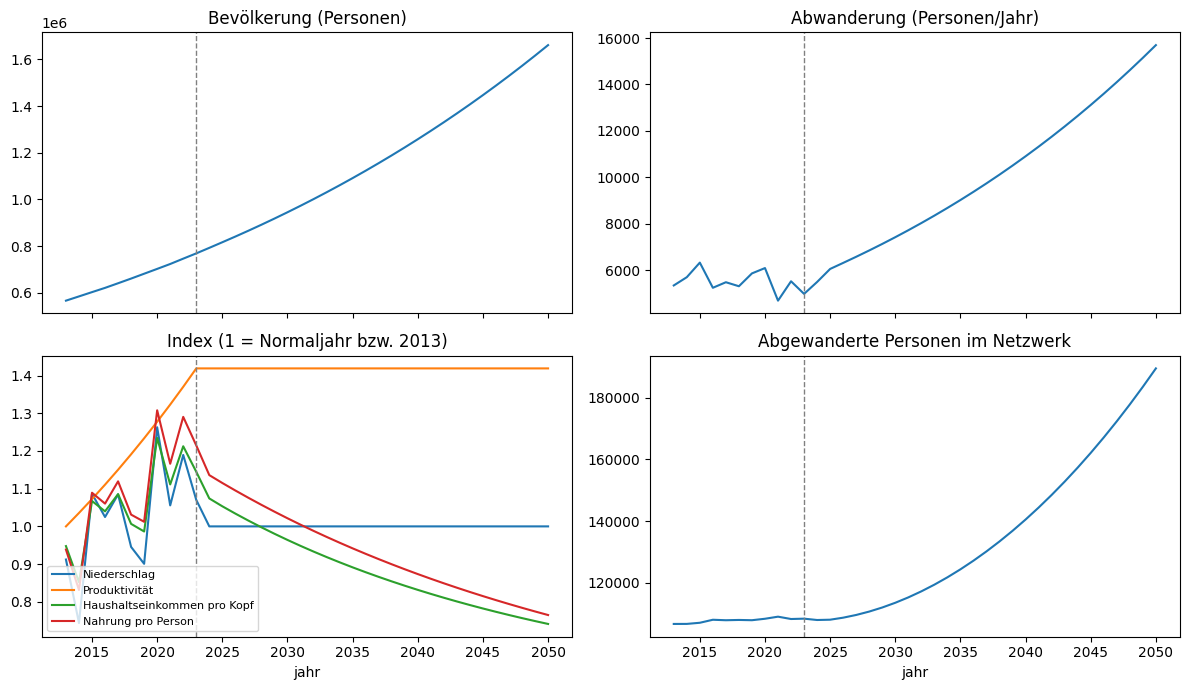

In [11]:
#------------------------------------------------------------------------------
# Zeitverlauf der Kenngrössen
#------------------------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
basis["bevoelkerung"].plot(ax=axes[0, 0], title="Bevölkerung (Personen)")
basis["abwanderung"].plot(ax=axes[0, 1], title="Abwanderung (Personen/Jahr)")
basis["niederschlag_index"].plot(ax=axes[1, 0], title="Index (1 = Normaljahr bzw. 2013)", label="Niederschlag")
basis["produktivitaet_index"].plot(ax=axes[1, 0], label="Produktivität")
basis["haushaltseinkommen_index"].plot(ax=axes[1, 0], label="Haushaltseinkommen pro Kopf")
basis["nahrung_pk_index"].plot(ax=axes[1, 0], label="Nahrung pro Person")
axes[1, 0].legend(fontsize=8)
basis["abgewanderte"].plot(ax=axes[1, 1], title="Abgewanderte Personen im Netzwerk")
for ax in axes.flat:
    ax.axvline(2023, color="grey", ls="--", lw=1)
fig.tight_layout()
plt.show()

#### **Erkenntnisse**

Bis **2023** hält die Produktivität mit der Bevölkerung Schritt, danach sinkt das Einkommen pro Kopf und die Abwanderung steigt.

**Bis 2023**
- Die Abwanderungsrate sinkt von **0.94 %** auf **0.65 %**, weil der Produktivitätstrend das Einkommen pro Kopf erhöht und der Anteil der Abgewanderten an der wachsenden Bevölkerung sinkt
- Die Dürre **2014** erhöht die Rate erst **2015** auf **1.05 %**

**Ab 2024**
- Die Bevölkerung wächst auf **1.66** Mio. Personen (**2050**)
- Die Abwanderung steigt von rund **5'000** auf **15'700** Personen pro Jahr, die Rate von **0.65 %** auf **0.95 %**
- Ursache ist die Annahme stagnierender Produktivität bei weiter wachsender Bevölkerung, nicht der Niederschlag
- Der Netzwerkfaktor sinkt bis **2050** auf **0.80** und dämpft den Anstieg, weil die Bevölkerung schneller wächst als die Zahl der Abgewanderten

Ob die Entwicklung bis **2023** mit den Beobachtungen übereinstimmt, zeigt der Vergleich mit den Volkszählungen.

## **2.6) Validierung**

Validiert wird auf drei Ebenen. Der Gesamtverlauf wird an der Volkszählung geprüft, der wichtigste Übertragungskanal an Daten ausserhalb der Schätzperiode und die Numerik an kleineren Zeitschritten.

### **2.6.1) Backtest Bevölkerung und Migration**

Die Bevölkerung **2023** und die Lebenszeitwegzüge der beiden Volkszählungen wurden weder für Parameter noch für die Kalibrierung verwendet. Die Migrationsfenster sind nur teilweise unabhängig.

**Daten (Backtest):**
- `bev_beobachtet` aus Abschnitt `2.2.2) Bevölkerung und Migration`: Volkszählung **2023**
- `migration`: Wegzüge und Zuzüge Mai **2018** bis **2023**
- `raten`: Wegzugsraten der Fenster **2008** bis **2013** und **2018** bis **2023**
- `migration`: Lebenszeitwegzüge der Volkszählungen **2013** und **2023**
- `ansd_bevoelkerung_kaffrine.csv`: ANSD-Schätzungen und -Projektionen **2009** bis **2021**, nur zur Einordnung, keine Messungen

**Vorgehen:**
1. Bevölkerung **2023**, Wegzüge und Zuzüge **2018** bis **2022** mit den Daten vergleichen, Fehlermass ist der relative Fehler
2. Prüfen, welches natürliche Wachstum die Volkszählung **2023** treffen würde
3. Richtung der Abwanderungsrate mit beiden Volkszählungsfenstern vergleichen
4. Rückgang des Anteils der Abgewanderten an der Bevölkerung mit den Lebenszeitwegzügen vergleichen
5. Bevölkerung und Abwanderungsrate grafisch mit den Daten vergleichen

In [12]:
#------------------------------------------------------------------------------
# Vergleich mit den Volkszählungen
#------------------------------------------------------------------------------
vergleich = pd.DataFrame({
    "Simulation": [basis.loc[2023, "bevoelkerung"], basis.loc[2018:2022, "abwanderung"].sum(),
                   basis.loc[2018:2022, "zuzug"].sum()],
    "Referenz": [bev_beobachtet[2023], migration["wegzuege_5_jahre"], migration["zuzuege_5_jahre"]],
    "Art": ["unabhängig", "kalibriert", "Konsistenz"],
}, index=["Bevölkerung 2023", "Binnenwegzüge Mai 2018-2023", "Binnenzuzüge Mai 2018-2023"])
vergleich["Fehler"] = vergleich["Simulation"] / vergleich["Referenz"] - 1
display(vergleich.style.format({"Simulation": zahl, "Referenz": zahl, "Fehler": lambda x: prozent(x, 1, True)}))

#------------------------------------------------------------------------------
# Natürliches Wachstum, das die Volkszählung 2023 treffen würde
#------------------------------------------------------------------------------
for r in [0.0336, 0.0379, 0.040, 0.042]:
    df = simuliere(ns_basis, ref, with_overrides(rate_natuerliches_wachstum_2013=r, rate_natuerliches_wachstum=r),
                   name=f"r{int(r * 1e4)}")
    print(f"Natürliches Wachstum konstant {prozent(r, 2)}: Bevölkerung 2023 = {zahl(df.loc[2023, 'bevoelkerung'])}")

print(f"\nAbwanderungsrate im Modell 2013: {prozent(basis.loc[2013, 'abwanderungsrate'], 2)}, "
      f"Mittel 2018-2022: {prozent(basis.loc[2018:2022, 'abwanderungsrate'].mean(), 2)}")

#------------------------------------------------------------------------------
# Anteil der Abgewanderten an der Bevölkerung: Modell und Lebenszeitwegzüge
#------------------------------------------------------------------------------
anteil_modell = basis["abgewanderte"] / basis["bevoelkerung"]
anteil_daten = pd.Series({2013: migration["wegzuege_lebenszeit_2013"] / bev_beobachtet[2013],
                          2023: migration["wegzuege_lebenszeit"] / bev_beobachtet[2023]})
for name, a in [("Modell", anteil_modell), ("Lebenszeitwegzüge", anteil_daten)]:
    print(f"Anteil Abgewanderte {name}: 2013 {prozent(a[2013])}, 2023 {prozent(a[2023])}, "
          f"Faktor 2023/2013 {a[2023] / a[2013]:.2f}")

,Simulation,Referenz,Art,Fehler
Bevölkerung 2023,769'319,820'405,unabhängig,-6.2 %
Binnenwegzüge Mai 2018-2023,27'475,27'588,kalibriert,-0.4 %
Binnenzuzüge Mai 2018-2023,12'662,13'645,Konsistenz,-7.2 %


Natürliches Wachstum konstant 3.36 %: Bevölkerung 2023 = 752'073
Natürliches Wachstum konstant 3.79 %: Bevölkerung 2023 = 783'829
Natürliches Wachstum konstant 4.00 %: Bevölkerung 2023 = 799'780


Natürliches Wachstum konstant 4.20 %: Bevölkerung 2023 = 815'248

Abwanderungsrate im Modell 2013: 0.94 %, Mittel 2018-2022: 0.78 %
Anteil Abgewanderte Modell: 2013 18.8 %, 2023 14.1 %, Faktor 2023/2013 0.75
Anteil Abgewanderte Lebenszeitwegzüge: 2013 13.2 %, 2023 9.8 %, Faktor 2023/2013 0.74


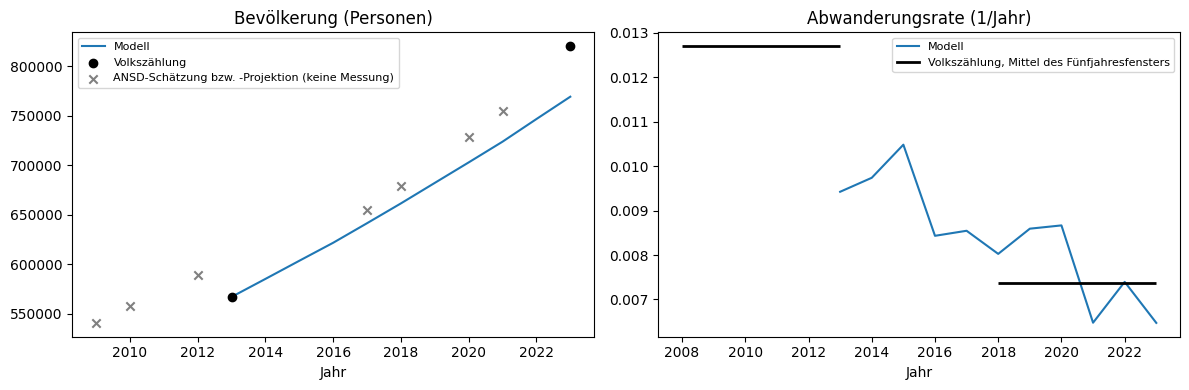

In [13]:
#------------------------------------------------------------------------------
# Grafik Backtest: Modell gegen Volkszählungen und ANSD-Schätzungen
#------------------------------------------------------------------------------
bev_alle = pd.read_csv(DATA_RAW / "ansd_bevoelkerung_kaffrine.csv").set_index("jahr")
bev_schaetzung = bev_alle.loc[(bev_alle.index >= 2009) & (bev_alle.index <= LETZTES_DATENJAHR)
                              & bev_alle["datentyp"].isin(["Schaetzung", "Projektion"]), "bevoelkerung"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ax = axes[0]
basis.loc[2013:2023, "bevoelkerung"].plot(ax=ax, label="Modell")
ax.scatter(bev_beobachtet.index, bev_beobachtet.values, color="black", zorder=3, label="Volkszählung")
ax.scatter(bev_schaetzung.index, bev_schaetzung.values, marker="x", color="grey", zorder=3,
           label="ANSD-Schätzung bzw. -Projektion (keine Messung)")
ax.set(title="Bevölkerung (Personen)", xlabel="Jahr")
ax.legend(fontsize=8)

ax = axes[1]
basis.loc[2013:2023, "abwanderungsrate"].plot(ax=ax, label="Modell")
for (start, ende), fenster in [((2008, 2013), "Fenster 2008-2013"), ((2018, 2023), "Fenster 2018-2023")]:
    ax.hlines(raten.loc[fenster, "wegzug"], start, ende, color="black", lw=2)
ax.plot([], [], color="black", lw=2, label="Volkszählung, Mittel des Fünfjahresfensters")
ax.set(title="Abwanderungsrate (1/Jahr)", xlabel="Jahr")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

#### **Erkenntnisse**

Das Modell trifft die Grössenordnung, unterschätzt aber das Bevölkerungswachstum.

**Bevölkerung**
- Die Bevölkerung **2023** wird um **6.2 %** unterschätzt
- Das Modell rechnet mit den Volkszählungswerten des natürlichen Wachstums, linear von **3.79 %** (**2013**) auf **3.36 %** (**2023**). Erst ein konstantes Wachstum von gut **4.2 %** würde die Volkszählung treffen
- Die Lücke ist mit den beobachteten Geburten-, Sterbe- und Migrationsraten nicht erklärbar. Mögliche Gründe sind eine Untererfassung **2013** oder Unterschiede zwischen den Volkszählungen

**Migration**
- **Wegzüge:** Die Abweichung von **−0.4 %** ist Folge der Kalibrierung und keine Validierung
- **Zuzüge:** Die Abweichung von **−7.2 %** folgt aus der zu tiefen Modellbevölkerung
- **Netzwerkanteil:** Im Modell sinkt der Anteil der Abgewanderten an der Bevölkerung von **18.8 %** auf **14.1 %**, bei den Lebenszeitwegzügen der Volkszählungen von **13.2 %** auf **9.8 %**. Der Rückgang ist mit dem Faktor **0.75** und **0.74** fast gleich. Das Niveau ist nicht vergleichbar, weil Lebenszeitwegzüge alle in Kaffrine Geborenen zählen, die anderswo in Senegal leben, und das Modell eine Verweildauer von **20** Jahren annimmt
- **Richtung:** Im Modell sinkt die Abwanderungsrate von **0.94 %** (**2013**) auf im Mittel **0.78 %** (**2018** bis **2022**). Die Daten zeigen dieselbe Richtung, aber stärker, von **1.27 %** (**2008** bis **2013**) auf **0.74 %** (**2018** bis **2023**). Das Modell ist damit konsistent mit den Daten, bestätigt den Mechanismus aber nicht. Die Richtung folgt im Modell aus den Annahmen zu Produktivität, Einkommen und Netzwerk, das Fenster **2008** bis **2013** liegt vor dem Modellstart, und der Rückgang zwischen den Volkszählungen kann auch andere Ursachen haben
- **ANSD-Schätzungen:** Die Schätzungen und Projektionen zwischen den Volkszählungen liegen über dem Modell, die Schätzung **2012** sogar über der Volkszählung **2013**. Sie sind deshalb nur zur Einordnung geeignet, nicht als Vergleichswerte

Ein Backtest mit so wenigen unabhängigen Werten prüft die Wirkungsstärken kaum. Deshalb wird der wichtigste Übertragungskanal zusätzlich einzeln getestet.

### **2.6.2) Test ausserhalb der Stichprobe für den Ertrag**

Der Kanal Niederschlag → Ertrag trägt die gesamte Klimawirkung. Getestet wird, ob die Regression spätere Jahre vorhersagen kann, die nicht in der Schätzung enthalten sind.

**Daten (Kalibrierung):**
- `ertrag` aus Abschnitt `2.2.3) Ertrag`, Jahre bis **2018**

**Daten (Backtest):**
- `ertrag`, Jahre **2019** bis **2023**

**Vorgehen:**
1. Elastizität und Trend nur mit den Jahren bis **2018** schätzen
2. Erträge **2019** bis **2023** mit dem gemessenen Niederschlag vorhersagen
3. Zum Vergleich ein Modell nur mit Trend ohne Niederschlag vorhersagen lassen
4. Mittleren absoluten Fehler beider Modelle vergleichen

In [14]:
#------------------------------------------------------------------------------
# Ertrag: Schätzung bis 2018, Vorhersage 2019-2023
#------------------------------------------------------------------------------
def ertrag_backtest(ertrag, niederschlag, ref, bis=2018):
    """
    Test ausserhalb der Stichprobe: Schätzung bis `bis`, Vorhersage der späteren Jahre.
    Vergleich mit einem Modell nur mit Trend, um den Beitrag des Niederschlags zu prüfen.
    """
    zeilen = []
    for kultur in ertrag.columns:
        reihe = ertrag[kultur].dropna()
        voll = schaetze_ertrag_elastizitaet(reihe, niederschlag, ref, bis=bis)
        # Vergleichsmodell nur mit Trend
        train = reihe.loc[:bis]
        t0 = train.index.values.mean()
        X = np.column_stack([np.ones(len(train)), train.index.values - t0])
        k, *_ = np.linalg.lstsq(X, np.log(train.values), rcond=None)
        for jahr in reihe.loc[bis + 1:].index:
            idx = niederschlag[jahr] / ref
            mit_regen = np.exp(voll["a"] + voll["elastizitaet"] * np.log(idx) + voll["trend"] * (jahr - voll["t0"]))
            nur_trend = np.exp(k[0] + k[1] * (jahr - t0))
            zeilen.append({"kultur": kultur, "jahr": jahr, "niederschlagsindex": idx, "beobachtet": reihe[jahr],
                           "mit_niederschlag": mit_regen, "nur_trend": nur_trend})
    df = pd.DataFrame(zeilen)
    df["fehler_mit_niederschlag"] = df["mit_niederschlag"] / df["beobachtet"] - 1
    df["fehler_nur_trend"] = df["nur_trend"] / df["beobachtet"] - 1
    return df


bt_ertrag = ertrag_backtest(ertrag, niederschlag, ref, bis=2018)
display(bt_ertrag.style.format({"niederschlagsindex": "{:.2f}", "beobachtet": zahl, "mit_niederschlag": zahl,
                                "nur_trend": zahl, "fehler_mit_niederschlag": lambda x: prozent(x, 1, True),
                                "fehler_nur_trend": lambda x: prozent(x, 1, True)}).hide(axis="index"))
mae = bt_ertrag.groupby("kultur")[["fehler_mit_niederschlag", "fehler_nur_trend"]].apply(lambda d: d.abs().mean())
mae.style.format(lambda x: prozent(x))

kultur,jahr,niederschlagsindex,beobachtet,mit_niederschlag,nur_trend,fehler_mit_niederschlag,fehler_nur_trend
Erdnuss (arachide d'huilerie),2022,1.19,1'332,1'752,1'341,+31.5 %,+0.7 %
Erdnuss (arachide d'huilerie),2023,1.07,1'529,1'594,1'374,+4.2 %,-10.1 %
Hirse (mil),2019,0.90,1'326,1'079,1'129,-18.6 %,-14.8 %
Hirse (mil),2020,1.26,1'339,1'397,1'170,+4.4 %,-12.6 %
Hirse (mil),2021,1.06,1'450,1'294,1'213,-10.8 %,-16.4 %
Hirse (mil),2022,1.19,1'658,1'454,1'257,-12.3 %,-24.2 %
Hirse (mil),2023,1.07,1'650,1'412,1'303,-14.4 %,-21.1 %


,fehler_mit_niederschlag,fehler_nur_trend
kultur,,
Erdnuss (arachide d'huilerie),17.9 %,5.4 %
Hirse (mil),12.1 %,17.8 %


#### **Erkenntnisse**

Der Niederschlag verbessert die Vorhersage nur für Hirse. Der Kanal Niederschlag → Ertrag ist damit plausibel, seine Stärke aber unsicher.

- **Hirse:** Mit Niederschlag beträgt der mittlere absolute Fehler **12.1 %**, nur mit Trend **17.8 %**
- **Erdnuss:** Mit Niederschlag **17.9 %**, nur mit Trend **5.4 %**. Die Schätzung bis **2018** beruht auf nur **7** Jahren, und die Elastizität wird im nassen Jahr **2022** stark überschätzt
- **Folgerung:** Die Elastizität von **0.7** ist eher eine obere Grenze. Die Sensitivitätsanalyse prüft deshalb die ganze Spannweite von **0.46** bis **0.94**

Neben den Daten muss auch die Numerik des Modells geprüft werden.

### **2.6.3) Numerische Robustheit**

Mit einem Zeitschritt von einem Jahr verletzt das Modell die Faustregel für die Verzögerung. Geprüft wird, ob kleinere Zeitschritte die Ergebnisse verändern.

**Daten (Szenario):**
- `ns_basis` aus Abschnitt `2.4.2) Parameter und Kalibrierung`

**Vorgehen:**
1. Basislauf mit `dt` = 1, 0.5 und 0.25 Jahren rechnen
2. Niederschlag und Produktivität bleiben Jahreswerte, die für das ganze Jahr gelten
3. Bevölkerung **2023** und **2050** sowie kumulierte Abwanderung **2024** bis **2049** vergleichen

In [15]:
#------------------------------------------------------------------------------
# Vergleich verschiedener Zeitschritte
#------------------------------------------------------------------------------
zeilen = {}
for dt in [1, 0.5, 0.25]:
    df = simuliere(ns_basis, ref, with_overrides(dt=dt), name=f"dt_{str(dt).replace('.', '_')}")
    zeilen[f"dt = {dt}"] = {"Bevölkerung 2023": df.loc[2023, "bevoelkerung"],
                            "Bevölkerung 2050": df.loc[2050, "bevoelkerung"],
                            "Abwanderung 2024-2049": df.loc[2024:2049, "abwanderung"].sum()}
zeitschritt = pd.DataFrame(zeilen).T
zeitschritt["Abweichung Abwanderung"] = zeitschritt["Abwanderung 2024-2049"] / zeitschritt.iloc[0]["Abwanderung 2024-2049"] - 1
zeitschritt.style.format({"Bevölkerung 2023": zahl, "Bevölkerung 2050": zahl, "Abwanderung 2024-2049": zahl,
                          "Abweichung Abwanderung": lambda x: prozent(x, 1, True)})

,Bevölkerung 2023,Bevölkerung 2050,Abwanderung 2024-2049,Abweichung Abwanderung
dt = 1,769'319,1'660'666,256'791,+0.0 %
dt = 0.5,771'095,1'671'203,261'243,+1.7 %
dt = 0.25,771'961,1'676'558,263'533,+2.6 %


#### **Erkenntnisse**

Der Jahresschritt verzerrt die Bestände kaum, die kumulierte Abwanderung aber leicht.

- **Bevölkerung:** Die Unterschiede liegen unter **1 %**
- **Abwanderung:** Mit `dt` = 0.25 liegt die kumulierte Abwanderung um **2.6 %** höher, weil die Rückkopplungen innerhalb des Jahres reagieren
- **Entscheid:** `dt` = 1 bleibt, weil der Unterschied klein gegenüber der Unsicherheit der Parameter ist und der Jahrestakt der Ernte entspricht

Neben Daten und Numerik wird die innere Konsistenz des Modells geprüft.

### **2.6.4) Plausibilitätsprüfung**

Ein Modell kann gute Ergebnisse liefern und trotzdem innere Fehler haben. Die Prüfung stellt sicher, dass die Grundregeln der Systemdynamik eingehalten sind.

**Daten (Szenario):**
- `basis` aus Abschnitt `2.5) Basislauf`
- Szenario `trockener` mit dauerhaft **15 %** weniger Niederschlag, hier neu gerechnet

**Vorgehen:**
1. Anfangswerte mit dem Anfangszustand vergleichen
2. Bestandsbilanz prüfen, ein Stock ändert sich nur über seine Flows
3. Keine negativen Bestände und Raten zulassen
4. Richtung prüfen, weniger Niederschlag muss mehr Abwanderung ergeben
5. Jeden Parameter auf Einheit, Quelle und Status prüfen

In [16]:
#------------------------------------------------------------------------------
# Plausibilitätsprüfung (bricht bei einem Fehler ab)
#------------------------------------------------------------------------------
p = PARAMS
abg_0 = p["abwanderungsrate_basis"].wert * p["bevoelkerung_0"].wert * p["verweildauer"].wert
assert np.isclose(basis.loc[2013, "bevoelkerung"], p["bevoelkerung_0"].wert)
assert np.isclose(basis.loc[2013, "abgewanderte"], abg_0)

# Bestandsbilanz bei dt = 1: B(t+1) = B(t) + Zuflüsse - Abflüsse
d = basis.loc[2013:2049]
soll_bev = d["bevoelkerung"] + d["natuerliches_wachstum"] + d["zuzug"] - d["abwanderung"]
soll_abg = d["abgewanderte"] + d["abwanderung"] - d["abgang_netzwerk"]
assert np.allclose(soll_bev.values, basis.loc[2014:2050, "bevoelkerung"].values, rtol=1e-9)
assert np.allclose(soll_abg.values, basis.loc[2014:2050, "abgewanderte"].values, rtol=1e-9)

assert (basis[["bevoelkerung", "abgewanderte", "abwanderung", "abwanderungsrate"]] >= 0).all().all()

trocken_test = simuliere(niederschlag_szenario(niederschlag, ref, aenderung=-0.15), ref, name="test_trocken")
assert trocken_test.loc[2024:2050, "abwanderung"].sum() > basis.loc[2024:2050, "abwanderung"].sum()

for name, par in PARAMS.items():
    assert par.einheit and par.beschreibung and par.quelle, name
    assert par.status in {"Daten", "Kalibriert", "Annahme"}, name

print("Alle Prüfungen bestanden")

Alle Prüfungen bestanden


#### **Erkenntnisse**

Alle Prüfungen sind bestanden.

- **Bestandsbilanz:** Bevölkerung und Abgewanderte ändern sich exakt um ihre Flows
- **Wertebereich:** Keine negativen Bestände oder Raten
- **Richtung:** Ein trockeneres Klima erhöht die Abwanderung
- **Dokumentation:** Jeder Parameter hat Einheit, Quelle und Status

Das validierte Modell kann nun für Szenarien verwendet werden.

## **2.7) Szenarien**

Die Szenarien zeigen, wie das Modell auf unterschiedliche Annahmen für den Niederschlag ab **2024** reagiert. Sie sind keine Prognosen. Für den westlichen Sahel projizieren Klimamodelle eher eine Abnahme des Niederschlags, die Stärke für Kaffrine ist aber unbekannt und deshalb eine Annahme.

**Daten (Szenario):**
- `niederschlag` bis **2023**, danach Szenario

**Vorgehen:**
1. Drei Niederschlagsszenarien definieren
   - **basis:** jedes Jahr ein Normaljahr
   - **duerren:** alle fünf Jahre **30 %** weniger Niederschlag, erstmals **2024**
   - **trockener:** dauerhaft **15 %** weniger Niederschlag
2. Bevölkerung **2050** und kumulierte Abwanderung **2024** bis **2050** vergleichen
3. Modellbevölkerung der ANSD-Projektion gegenüberstellen

In [17]:
#------------------------------------------------------------------------------
# Szenarien rechnen
#------------------------------------------------------------------------------
szenarien = {
    "basis": ns_basis,
    "duerren": niederschlag_szenario(niederschlag, ref, duerre_alle=5, duerre_staerke=0.3),
    "trockener": niederschlag_szenario(niederschlag, ref, aenderung=-0.15),
}
laeufe = {name: simuliere(ns, ref, name=name) for name, ns in szenarien.items()}

tabelle = pd.DataFrame({name: {
    "Bevölkerung 2050": df.loc[2050, "bevoelkerung"],
    "Abwanderung 2024-2050": df.loc[2024:2050, "abwanderung"].sum(),
} for name, df in laeufe.items()}).T
tabelle["Mehr als basis"] = tabelle["Abwanderung 2024-2050"] - tabelle.loc["basis", "Abwanderung 2024-2050"]
tabelle["Mehr als basis (%)"] = tabelle["Abwanderung 2024-2050"] / tabelle.loc["basis", "Abwanderung 2024-2050"] - 1
tabelle.style.format({"Bevölkerung 2050": zahl, "Abwanderung 2024-2050": zahl, "Mehr als basis": zahl,
                      "Mehr als basis (%)": lambda x: prozent(x, 1, True)})

,Bevölkerung 2050,Abwanderung 2024-2050,Mehr als basis,Mehr als basis (%)
basis,1'660'666,272'486,0,+0.0 %
duerren,1'647'861,281'801,9'315,+3.4 %
trockener,1'629'943,293'013,20'527,+7.5 %


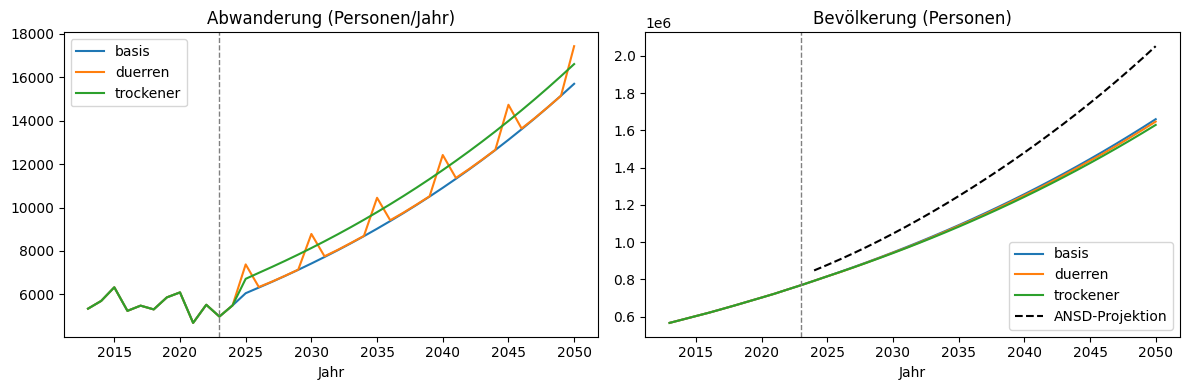

In [18]:
#------------------------------------------------------------------------------
# Zeitverlauf der Szenarien und Vergleich mit der ANSD-Projektion
#------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, df in laeufe.items():
    df["abwanderung"].plot(ax=axes[0], label=name)
    df["bevoelkerung"].plot(ax=axes[1], label=name)
bev_projektion.loc[2024:2050].plot(ax=axes[1], label="ANSD-Projektion", ls="--", color="black")
axes[0].set(title="Abwanderung (Personen/Jahr)", xlabel="Jahr")
axes[1].set(title="Bevölkerung (Personen)", xlabel="Jahr")
for ax in axes:
    ax.axvline(2023, color="grey", ls="--", lw=1)
    ax.legend()
fig.tight_layout()
plt.show()

#### **Erkenntnisse**

Dürren erhöhen die Abwanderung spürbar, verändern das Gesamtbild aber wenig.

**Klimawirkung**
- **Wiederkehrende Dürren:** **+3.4 %** kumulierte Abwanderung bis **2050**, rund **9'300** Personen
- **Trockeneres Klima:** **+7.5 %**, rund **20'500** Personen
- Jede Dürre zeigt sich ein Jahr später als Spitze der Abwanderung

**Vergleich mit der ANSD-Projektion**
- Das Modell erreicht **2050** rund **1.66** Mio. Personen, die ANSD-Projektion **2.05** Mio.
- Gründe sind die Lücke aus dem Backtest, die konstante Wachstumsrate ab **2024** ohne Altersstruktur und die steigende Abwanderung bei stagnierender Produktivität

Wie belastbar diese Zahlen sind, hängt von den Annahmen ab, die nun einzeln variiert werden.

## **2.8) Sensitivität**

Die Sensitivitätsanalyse zeigt, welche Parameter die Ergebnisse treiben. Gemessen werden zwei Grössen im Szenario `duerren`. Die kumulierte Abwanderung **2024** bis **2050** zeigt, was die Abwanderung insgesamt treibt. Die Zusatzabwanderung durch Dürren, also die Differenz der Szenarien `duerren` und `basis`, beantwortet die Leitfrage.

### **2.8.1) Parameterbandbreiten**

Daten-Parameter werden innerhalb ihrer belegten Spannweite variiert, Annahmen werden halbiert und verdoppelt.

**Daten (Szenario):**
- `szenarien["duerren"]` und `szenarien["basis"]` aus Abschnitt `2.7) Szenarien`
- `raten` und `schaetzung` aus Abschnitt `2.2) Daten` für die Bandbreiten

**Vorgehen:**
1. Bandbreite je Parameter festlegen
2. Jeden Parameter einzeln auf den tiefen und den hohen Wert setzen
3. Jeden Lauf auch im Szenario `basis` rechnen, um die Zusatzabwanderung durch Dürren zu erhalten
4. Änderung beider Grössen gegenüber der Referenz darstellen

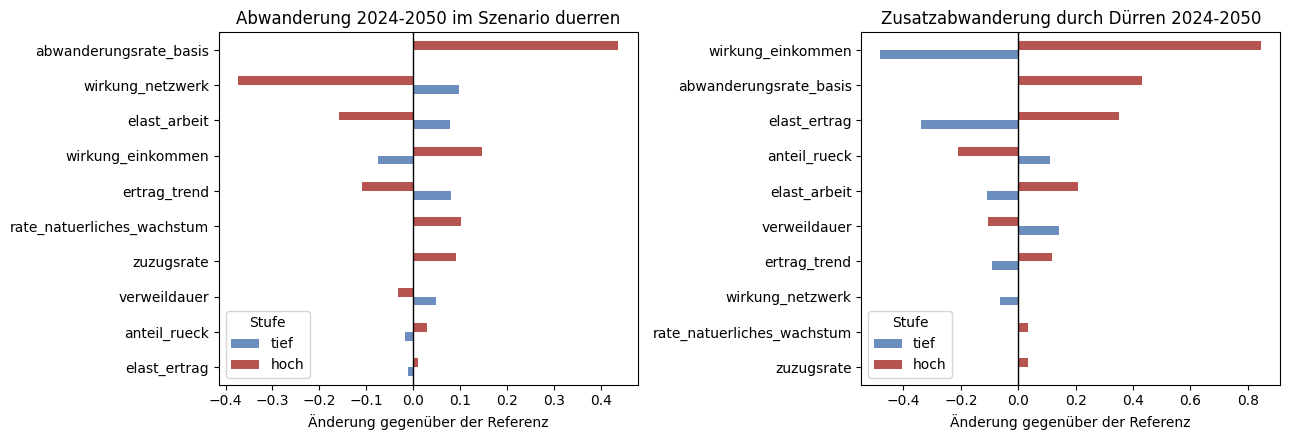

Zusatzabwanderung durch Dürren: Referenz 9'315 Personen, Einzelvariation 4'845 bis 17'195 Personen


,Wert tief,Wert hoch,Änderung tief,Änderung hoch,Zusatz tief,Zusatz hoch,Grundlage
Parameter,,,,,,,
wirkung_einkommen,0.5,2,-7.4 %,+14.6 %,-48.0 %,+84.6 %,Annahme: halbiert und verdoppelt
abwanderungsrate_basis,0.0094,0.01619,+0.0 %,+43.8 %,+0.0 %,+43.2 %,Daten: kalibriert und skaliert mit dem Verhältnis der Fenster 2008-2013 zu 2018-2023
elast_ertrag,0.4631,0.9447,-1.1 %,+1.1 %,-33.9 %,+35.1 %,Daten: Hirse und Erdnuss
anteil_rueck,0.075,0.3,-1.7 %,+3.0 %,+11.0 %,-21.1 %,Annahme: halbiert und verdoppelt
elast_arbeit,0.15,0.6,+7.9 %,-15.7 %,-10.8 %,+21.0 %,Annahme: halbiert und verdoppelt
verweildauer,10,40,+4.8 %,-3.3 %,+14.1 %,-10.4 %,Annahme: halbiert und verdoppelt
ertrag_trend,0.02238,0.05063,+8.0 %,-11.0 %,-9.0 %,+11.9 %,Daten: Erdnuss und Hirse
wirkung_netzwerk,0.25,1,+9.9 %,-37.4 %,-6.3 %,-0.2 %,Annahme: halbiert und verdoppelt
rate_natuerliches_wachstum,0.0336,0.0379,+0.0 %,+10.3 %,+0.0 %,+3.5 %,Daten: 2023 und 2013


In [19]:
#------------------------------------------------------------------------------
# Bandbreiten und Einzelvariation (Tornado)
#------------------------------------------------------------------------------
def bandbreiten(raten, schaetzung):
    """
    Bandbreiten für die Sensitivitätsanalyse.
    Daten-Parameter: belegte Spannweite (zweites Erhebungsfenster bzw. beide Kulturen).
    Annahmen: Halbierung und Verdoppelung.
    """
    b = {
        "rate_natuerliches_wachstum": (0.0336, 0.0379, "Daten: 2023 und 2013"),
        "abwanderungsrate_basis": (PARAMS["abwanderungsrate_basis"].wert,
                                   PARAMS["abwanderungsrate_basis"].wert * raten.loc["Fenster 2008-2013", "wegzug"]
                                   / raten.loc["Fenster 2018-2023", "wegzug"],
                                   "Daten: kalibriert und skaliert mit dem Verhältnis der Fenster 2008-2013 zu 2018-2023"),
        "zuzugsrate": (raten.loc["Fenster 2018-2023", "zuzug"], raten.loc["Fenster 2008-2013", "zuzug"],
                       "Daten: Fenster 2018-2023 und 2008-2013"),
        "elast_ertrag": (schaetzung["elastizitaet"].min(), schaetzung["elastizitaet"].max(), "Daten: Hirse und Erdnuss"),
        "ertrag_trend": (schaetzung["trend"].min(), schaetzung["trend"].max(), "Daten: Erdnuss und Hirse"),
    }
    for k in ["verweildauer", "elast_arbeit", "anteil_rueck", "wirkung_einkommen", "wirkung_netzwerk"]:
        b[k] = (PARAMS[k].wert * 0.5, PARAMS[k].wert * 2.0, "Annahme: halbiert und verdoppelt")
    return pd.DataFrame(b, index=["tief", "hoch", "grundlage"]).T


bb = bandbreiten(raten, schaetzung)
kumuliert = lambda df: df.loc[2024:2050, "abwanderung"].sum()
duerren_total = kumuliert(laeufe["duerren"])
zusatz_ref = duerren_total - kumuliert(laeufe["basis"])  # Zusatzabwanderung durch Dürren

zeilen = []
for k, (tief, hoch, grundlage) in bb.iterrows():
    for stufe, wert in [("tief", tief), ("hoch", hoch)]:
        p_ = with_overrides(**{k: wert})
        d_ = kumuliert(simuliere(szenarien["duerren"], ref, p_, name=f"{k}_{stufe}_d"))
        b_ = kumuliert(simuliere(szenarien["basis"], ref, p_, name=f"{k}_{stufe}_b"))
        zeilen.append({"Parameter": k, "Stufe": stufe, "Wert": wert,
                       "Änderung": d_ / duerren_total - 1, "Zusatz": d_ - b_})
erg = pd.DataFrame(zeilen)
sens = erg.pivot(index="Parameter", columns="Stufe", values="Änderung")
sens = sens.reindex(sens.abs().max(axis=1).sort_values().index)
sens_zusatz = erg.pivot(index="Parameter", columns="Stufe", values="Zusatz") / zusatz_ref - 1
sens_zusatz = sens_zusatz.reindex(sens_zusatz.abs().max(axis=1).sort_values().index)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, werte, titel in [(axes[0], sens, "Abwanderung 2024-2050 im Szenario duerren"),
                         (axes[1], sens_zusatz, "Zusatzabwanderung durch Dürren 2024-2050")]:
    werte[["tief", "hoch"]].plot.barh(ax=ax, color=["#6c8ebf", "#b85450"])
    ax.axvline(0, color="black", lw=1)
    ax.set(xlabel="Änderung gegenüber der Referenz", ylabel="", title=titel)
fig.tight_layout()
plt.show()

print(f"Zusatzabwanderung durch Dürren: Referenz {zahl(zusatz_ref)} Personen, "
      f"Einzelvariation {zahl(erg['Zusatz'].min())} bis {zahl(erg['Zusatz'].max())} Personen")

tabelle_sens = bb.rename(columns={"tief": "Wert tief", "hoch": "Wert hoch", "grundlage": "Grundlage"})
tabelle_sens = tabelle_sens.join(sens.rename(columns={"tief": "Änderung tief", "hoch": "Änderung hoch"}))
tabelle_sens = tabelle_sens.join(sens_zusatz.rename(columns={"tief": "Zusatz tief", "hoch": "Zusatz hoch"}))
spalten = ["Änderung tief", "Änderung hoch", "Zusatz tief", "Zusatz hoch"]
tabelle_sens = tabelle_sens[["Wert tief", "Wert hoch"] + spalten + ["Grundlage"]]
tabelle_sens.loc[sens_zusatz.index[::-1]].style.format(
    {"Wert tief": "{:.4g}", "Wert hoch": "{:.4g}", **{s: (lambda x: prozent(x, 1, True)) for s in spalten}})

#### **Erkenntnisse**

Die gesamte Abwanderung hängt vor allem von Migrationsraten, Netzwerk und Bevölkerungsdynamik ab. Die Zusatzabwanderung durch Dürren, also die Antwort auf die Leitfrage, hängt vor allem von der Wirkung des Einkommens und der Klimakette ab.

**Gesamte Abwanderung, stärkste Einflüsse**
- **Migrationsraten:** Mit den Raten aus dem Fenster **2008** bis **2013** steigt die Abwanderung um **+43.8 %** (Wegzug) und **+9.2 %** (Zuzug)
- **Netzwerk:** `wirkung_netzwerk` verändert die Abwanderung um **−37.4 %** bis **+9.9 %**. Weil der Anteil der Abgewanderten an der wachsenden Bevölkerung sinkt, senkt ein stärkerer Netzwerkeffekt die Abwanderung. Es ist die wichtigste Annahme ohne Daten
- **Natürliches Wachstum:** Bleibt das Wachstum auf dem Wert von **2013**, steigt die Abwanderung um **+10.3 %**

**Gesamte Abwanderung, mittlere Einflüsse**
- `elast_arbeit`, `ertrag_trend` und `wirkung_einkommen` verändern die Abwanderung um **7 %** bis **16 %**

**Gesamte Abwanderung, kleine Einflüsse**
- **Klimakette:** `elast_ertrag` verändert die Abwanderung über die ganze Spannweite der Kulturen nur um **±1.1 %**
- **Rücküberweisungen und Verweildauer:** `anteil_rueck` und `verweildauer` wirken mit unter **5 %**. B2 ist im Modell schwach

**Zusatzabwanderung durch Dürren**
- **Bandbreite:** Referenz rund **9'300** Personen, je nach einzelner Annahme **4'845** bis **17'195** Personen
- **Wirkung des Einkommens:** `wirkung_einkommen` verändert die Zusatzabwanderung um **−48.0 %** bis **+84.6 %**. Diese Annahme ohne Daten bestimmt die Antwort auf die Leitfrage am stärksten
- **Klimakette:** `elast_ertrag` verändert sie um **−33.9 %** bis **+35.1 %**, die gesamte Abwanderung dagegen kaum
- **Basisrate:** Mit der Wegzugsrate des Fensters **2008** bis **2013** steigt sie um **+43.2 %**
- **Rücküberweisungen:** `anteil_rueck` verändert sie um **−21.1 %** bis **+11.0 %**. B2 dämpft den Dürreeffekt spürbar, obwohl es die gesamte Abwanderung kaum verändert
- **Netzwerk:** `wirkung_netzwerk` wirkt mit **−6.3 %** bis **−0.2 %** kaum auf die Zusatzabwanderung

Für belastbarere Aussagen zur Leitfrage wären vor allem Daten zur Reaktion der Abwanderung auf das Einkommen nötig, für die gesamte Abwanderung Daten zu Netzwerkeffekten und eine Migrationszeitreihe. Genauere Klimadaten helfen weniger.

### **2.8.2) Verzögerung**

Die Verzögerung wird separat mit 1, 2 und 3 Jahren geprüft. Eine Halbierung auf 0.5 Jahre wäre kürzer als der Zeitschritt und numerisch nicht sinnvoll.

**Daten (Szenario):**
- `szenarien["duerren"]` aus Abschnitt `2.7) Szenarien`

Verzögerung 1 Jahre: Abwanderung 2024-2050 +0.0 % gegenüber 1 Jahr
Verzögerung 2 Jahre: Abwanderung 2024-2050 -1.6 % gegenüber 1 Jahr


Verzögerung 3 Jahre: Abwanderung 2024-2050 -2.8 % gegenüber 1 Jahr


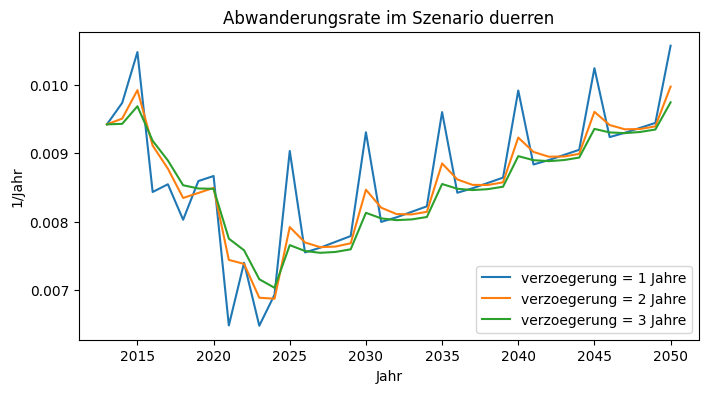

In [20]:
#------------------------------------------------------------------------------
# Verzögerung 1, 2 und 3 Jahre im Szenario duerren
#------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 4))
for tau in [1, 2, 3]:
    df = simuliere(szenarien["duerren"], ref, with_overrides(verzoegerung=tau), name=f"tau_{tau}")
    df["abwanderungsrate"].plot(ax=ax, label=f"verzoegerung = {tau} Jahre")
    print(f"Verzögerung {tau} Jahre: Abwanderung 2024-2050 "
          f"{prozent(df.loc[2024:2050, 'abwanderung'].sum() / duerren_total - 1, 1, True)} gegenüber 1 Jahr")
ax.set(title="Abwanderungsrate im Szenario duerren", xlabel="Jahr", ylabel="1/Jahr")
ax.legend()
plt.show()

#### **Erkenntnisse**

Die Länge der Verzögerung verschiebt den Zeitpunkt der Reaktion und glättet die Spitzen, die kumulierte Abwanderung ändert sich kaum.

- **2 Jahre:** **−1.6 %**
- **3 Jahre:** **−2.8 %**

Wichtiger als die Verzögerung ist die Annahme zur Produktivität nach **2023**.

### **2.8.3) Ertragstrend ab 2024**

Der Basislauf nimmt an, dass die Produktivität nach **2023** stagniert. Weil die Daten bis **2023** ein Wachstum von **2.2 %** bis **5.1 %** pro Jahr zeigen, wird geprüft, wie stark diese Annahme die Ergebnisse prägt.

**Daten (Szenario):**
- `ns_basis` und `szenarien["duerren"]` aus Abschnitt `2.7) Szenarien`

**Vorgehen:**
1. `ertrag_trend_zukunft` auf 0 %, 1 % und 2 % pro Jahr setzen
2. Kumulierte Abwanderung und Klimaeffekt der Dürren vergleichen

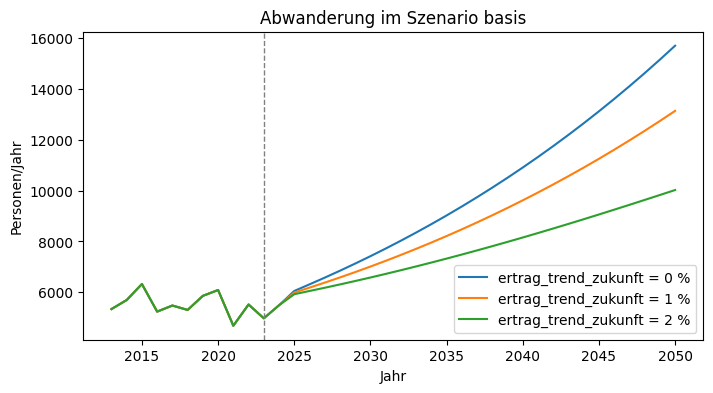

,Abwanderung 2024-2050 basis,Mehr durch Dürren,Änderung basis
0 %,272'486,9'315,+0.0 %
1 %,242'917,10'419,-10.9 %
2 %,208'840,11'661,-23.4 %


In [21]:
#------------------------------------------------------------------------------
# Produktivitätswachstum ab 2024
#------------------------------------------------------------------------------
zeilen = {}
fig, ax = plt.subplots(figsize=(8, 4))
for g in [0.0, 0.01, 0.02]:
    p = with_overrides(ertrag_trend_zukunft=g)
    b_ = simuliere(ns_basis, ref, p, name=f"trend_b_{int(g * 100)}")
    d_ = simuliere(szenarien["duerren"], ref, p, name=f"trend_d_{int(g * 100)}")
    b_["abwanderung"].plot(ax=ax, label=f"ertrag_trend_zukunft = {prozent(g, 0)}")
    zeilen[prozent(g, 0)] = {"Abwanderung 2024-2050 basis": b_.loc[2024:2050, "abwanderung"].sum(),
                             "Mehr durch Dürren": d_.loc[2024:2050, "abwanderung"].sum() - b_.loc[2024:2050, "abwanderung"].sum()}
ax.axvline(2023, color="grey", ls="--", lw=1)
ax.set(title="Abwanderung im Szenario basis", xlabel="Jahr", ylabel="Personen/Jahr")
ax.legend()
plt.show()
trend_tab = pd.DataFrame(zeilen).T
trend_tab["Änderung basis"] = trend_tab["Abwanderung 2024-2050 basis"] / trend_tab.iloc[0]["Abwanderung 2024-2050 basis"] - 1
trend_tab.style.format({"Abwanderung 2024-2050 basis": zahl, "Mehr durch Dürren": zahl,
                        "Änderung basis": lambda x: prozent(x, 1, True)})

#### **Erkenntnisse**

Die Annahme zur Produktivität prägt die Abwanderung weit stärker als jedes Niederschlagsszenario.

- **Gesamtwirkung:** Wächst die Produktivität ab **2024** um **2 %** pro Jahr, sinkt die kumulierte Abwanderung um **23.4 %**. Das ist rund dreimal so viel wie die Wirkung des trockeneren Klimas
- **Klimaeffekt:** Die zusätzliche Abwanderung durch Dürren steigt dabei leicht von **9'315** auf **11'661** Personen, weil ein höherer Ertrag bei gleicher prozentualer Einbusse absolut mehr verliert
- **Folgerung:** Der Anstieg der Abwanderungsrate im Basislauf ist eine Folge der Stagnationsannahme und keine Klimawirkung

Offen ist noch, ob die in LE1 vermutete Schleife R1 im Modell verstärkend wirkt.

### **2.8.4) R1 oder B1**

In LE1 wurde vermutet, dass fehlende Arbeitskräfte die Abwanderung verstärken (R1). Pro Kopf gerechnet wirkt R1 nur dann verstärkend, wenn die Produktion stärker auf die Arbeitskräfte reagiert als die Zahl der Köpfe.

**Daten (Szenario):**
- `szenarien["duerren"]` aus Abschnitt `2.7) Szenarien`

**Vorgehen:**
1. `elast_arbeit` auf 0, 0.3, 1.0 und 1.5 setzen
2. Abwanderungsrate im Zeitverlauf vergleichen

elast_arbeit = 0.0: Abwanderung 2024-2050 326'129
elast_arbeit = 0.3: Abwanderung 2024-2050 281'801
elast_arbeit = 1.0: Abwanderung 2024-2050 179'121


elast_arbeit = 1.5: Abwanderung 2024-2050 107'654


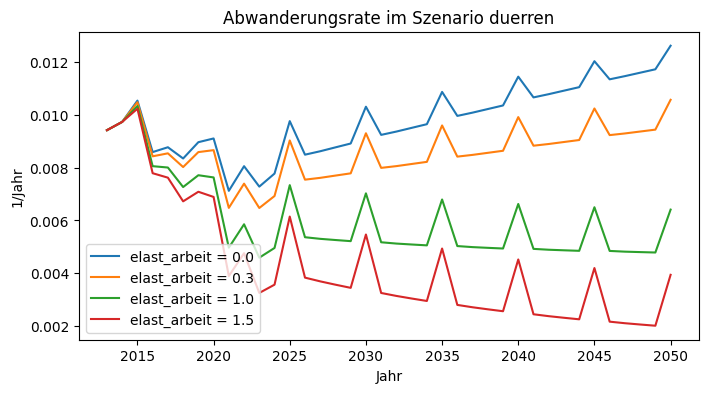

In [22]:
#------------------------------------------------------------------------------
# Abhängigkeit der Produktion von Arbeitskräften
#------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 4))
for e in [0.0, 0.3, 1.0, 1.5]:
    df = simuliere(szenarien["duerren"], ref, with_overrides(elast_arbeit=e), name=f"arbeit_{int(e * 10)}")
    df["abwanderungsrate"].plot(ax=ax, label=f"elast_arbeit = {e}")
    print(f"elast_arbeit = {e}: Abwanderung 2024-2050 {zahl(df.loc[2024:2050, 'abwanderung'].sum())}")
ax.set(title="Abwanderungsrate im Szenario duerren", xlabel="Jahr", ylabel="1/Jahr")
ax.legend()
plt.show()

#### **Erkenntnisse**

R1 ist im Modell schwach, B1 überwiegt.

- **Richtung:** Je stärker die Produktion an den Arbeitskräften hängt, desto tiefer ist die Abwanderung. Mit `elast_arbeit` = 1.5 sinkt sie auf **107'654** Personen, ohne Abhängigkeit (`elast_arbeit` = 0) steigt sie auf **326'129**
- **Grund:** Die Bevölkerung wächst trotz Abwanderung. Eine stärkere Abhängigkeit von Arbeitskräften heisst dann, dass die wachsende Bevölkerung auch mehr produziert
- **Folgerung:** Eine Abwanderungsspirale über fehlende Arbeitskräfte entsteht nur bei schrumpfender Bevölkerung. Das kommt unter den beobachteten Wachstumsraten nicht vor

Damit sind Struktur, Validierung, Szenarien und Sensitivität beisammen und können zusammengefasst werden.

## **2.9) Erkenntnisse und Limitationen**

Das Modell beantwortet die Fragestellung unter den dokumentierten Annahmen. Die Zahlen zeigen Wirkungsrichtungen und Grössenordnungen, keine Prognose der tatsächlichen Abwanderung.

| Frage | Ergebnis im Modell |
|---|---|
| Wie stark erhöhen Dürren die Abwanderung? | **+3.4 %** (wiederkehrende Dürren) bis **+7.5 %** (trockeneres Klima) bis **2050**, rund **9'300** bis **20'500** Personen. Bei den Dürren je nach Annahme **4'845** bis **17'195** Personen |
| Was treibt die Abwanderung am stärksten? | Verhältnis von Produktivität und Bevölkerung. **2 %** Produktivitätswachstum senkt die Abwanderung um **23.4 %** |
| Wie wirken die Rückkopplungen? | R2 (Netzwerk) ist die einflussreichste Annahme und dämpft im Basislauf, weil der Anteil der Abgewanderten sinkt. B1 überwiegt R1, B2 ist schwach |
| Wann wirkt eine Dürre? | im Folgejahr, längere Verzögerungen ändern die Summe nur um bis **−2.8 %** |
| Wie gut ist das Modell validiert? | Bevölkerung **2023** um **6.2 %** unterschätzt, Rückgang des Netzwerkanteils wie bei den Lebenszeitwegzügen, Richtung der Abwanderungsrate konsistent, Ertragskanal nur für Hirse besser als ein reiner Trend |

#### **Erkenntnisse**

Das Modell zeigt Dürren als messbaren, aber nicht dominierenden Treiber der dauerhaften Abwanderung. Entscheidend ist, ob die Landwirtschaft mit dem Bevölkerungswachstum Schritt hält.

**Limitationen der Daten**
- Nur ein unabhängiger Vergleichswert für die Bevölkerung, keine jährliche Migrationsreihe
- Ertragsreihen mit **9** und **12** Jahren, Elastizität unsicher und je nach Kultur verschieden
- Keine regionalen Daten zu Einkommen, Rücküberweisungen und Netzwerkeffekten

**Limitationen der Struktur**
- Nur dauerhafte Abwanderung, saisonale Migration ist rund viermal häufiger und wäre ein anderes Modell
- Keine Altersstruktur, konstantes natürliches Wachstum ab **2024**, keine eigene Wasserbilanz
- Ein Ertragsindex für Hirse und Erdnuss, obwohl beide unterschiedlich auf Regen reagieren
- Der Jahresschritt unterschätzt die kumulierte Abwanderung um rund **3 %**
- Die Nichtlinearitäten aus LE1 sind vereinfacht. Der Ertrag sinkt linear mit dem Niederschlag, ein Ernteausfall unter einer Mindestmenge Regen fehlt. Ebenso fehlen sehr arme Haushalte, die sich das Wegziehen nicht leisten können. Beides wäre ein Fall für ein agentenbasiertes Modell (LE3)

**Interpretation**
- Die Zahlen gelten unter den dokumentierten Annahmen und sind keine Prognose
- Kausale Wirkungen im Modell sind Annahmen oder Schätzungen. Die Regression des Ertrags zeigt einen Zusammenhang, keinen Beweis der Wirkung

Die Lösungsskizze LE4 in `LE4_scenario_analysis/` verbindet die Klimaszenarien mit Handlungsoptionen für Ertragsstabilität und Produktivität.